In [77]:
# Import Dependencies
import pandas as pd
import numpy as np
import yfinance as yf
from pathlib import Path
import time
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns


### Section 1 - Data Pipeline 

#### Functions:

In [78]:

TICKERS = ["XLC", "XLY", "XLP", "XLE", "XLF", "XLV", "XLI", "XLB", "XLRE", "XLK", "XLU", "SPY"]
CACHE_PATH = Path("sector_prices.csv")


def _download_prices(tickers, period=None, start=None, end=None):
    """
    Thin wrapper around yfinance. Pulls 'Adj Close' for all tickers and
    returns a wide DataFrame: index = date, columns = tickers.
    """
    raw = yf.download(tickers, period=period, start=start, end=end,
                       auto_adjust=False, progress=False)
    prices = raw["Adj Close"]
    if isinstance(prices, pd.Series):
        prices = prices.to_frame()
    return prices.sort_index()


def _get_latest_available_date(tickers):
    """
    Cheap staleness check: pull just the last 5 trading days rather than
    full history, and take the max date present. This tells us what
    yfinance considers 'the most recent available trading day' without
    the cost of a full re-download.
    """
    recent = _download_prices(tickers, period="5d")
    return recent.index.max()


def get_price_data(tickers=TICKERS, cache_path=CACHE_PATH):
    """
    Returns a wide DataFrame of Adj Close prices, backed by a local
    Parquet cache. Only hits the network if the cache is missing or stale.
    """
    if not cache_path.exists():
        # No cache at all: full history pull.
        prices = _download_prices(tickers, period="max")
        prices.to_csv(cache_path)
        return prices

    # Cache exists: load it and check staleness.
    cached = pd.read_csv(cache_path, index_col=0, parse_dates=True)
    cached_max_date = cached.index.max()
    latest_available = _get_latest_available_date(tickers)

    if cached_max_date >= latest_available:
        # Cache is already current; no network call needed beyond the 5d peek.
        return cached

    # Cache is stale: fetch from the cache's last date onward, with
    # deliberate overlap (not the day after) to catch any retroactive
    # adjustments to recent Adj Close values (dividends, splits, restatements).
    fetch_start = cached_max_date  # overlap by including this date again
    new_data = _download_prices(tickers, start=fetch_start)

    combined = pd.concat([cached, new_data])
    combined = combined[~combined.index.duplicated(keep="last")]
    combined = combined.sort_index()

    combined.to_csv(cache_path)
    return combined


def get_returns(tickers=TICKERS, cache_path=CACHE_PATH):
    """
    Returns simple (percent) daily returns, wide format, NaN rows dropped.
    """
    prices = get_price_data(tickers, cache_path)
    returns = prices.pct_change()
    returns = returns.dropna(how="any")
    return returns

#### Function Test:

In [79]:
# 1. First call: should trigger a full download (no cache file yet)
prices = get_price_data()
print(prices.shape)
prices.tail()

(8460, 12)


,SPY,XLB,XLC,XLE,XLF,XLI,XLK,XLP,XLRE,XLU,XLV,XLY
Date,,,,,,,,,,,,
2026-09-02,765.159973,52.950001,112.419998,65.099998,57.660000,172.779999,183.600006,85.529999,43.730000,42.669998,172.949997,114.860001
2026-09-03,773.169983,52.619999,113.379997,64.620003,58.560001,174.559998,185.970001,85.260002,44.250000,43.029999,173.259995,116.459999
2026-09-04,770.190002,52.439999,112.029999,64.059998,58.099998,175.270004,187.279999,84.580002,43.930000,43.080002,171.449997,114.910004
2026-09-08,765.960022,51.939999,111.519997,64.769997,57.299999,174.419998,187.869995,84.019997,43.900002,43.450001,167.130005,113.989998
2026-09-09,762.400024,51.389999,110.830002,65.309998,57.060001,171.789993,187.869995,83.050003,43.410000,42.939999,166.580002,112.459999


In [ ]:
# 2. Second call: should now read from cache and NOT do a full re-download
#    (you can verify this by timing it)

t0 = time.time()
prices2 = get_price_data()
print(time.time() - t0)

0.27710485458374023


In [ ]:
# 4. Now test the returns function
returns = get_returns()
returns.shape
returns.head()
returns.describe()

,SPY,XLB,XLC,XLE,XLF,XLI,XLK,XLP,XLRE,XLU,XLV,XLY
count,2066.000000,2066.000000,2066.000000,2066.000000,2066.000000,2066.000000,2066.000000,2066.000000,2066.000000,2066.000000,2066.000000,2066.000000
mean,0.000625,0.000447,0.000521,0.000640,0.000536,0.000568,0.000982,0.000388,0.000381,0.000463,0.000453,0.000489
std,0.012074,0.013814,0.013932,0.019954,0.014610,0.013425,0.016862,0.009849,0.013701,0.012825,0.011012,0.015047
min,-0.109424,-0.110084,-0.112795,-0.201412,-0.137093,-0.113442,-0.138139,-0.093957,-0.160011,-0.113577,-0.098610,-0.126686
25%,-0.004278,-0.006939,-0.005747,-0.009044,-0.005872,-0.005578,-0.007350,-0.004294,-0.006152,-0.005859,-0.005015,-0.006747
50%,0.000848,0.000672,0.001088,0.001150,0.000896,0.000919,0.001714,0.000557,0.000887,0.001057,0.000526,0.001267
75%,0.006437,0.007844,0.007632,0.010350,0.007491,0.007339,0.009986,0.005393,0.007291,0.006934,0.006009,0.008529
max,0.105019,0.117601,0.089901,0.160373,0.131566,0.126512,0.134257,0.085107,0.087801,0.127934,0.077057,0.108881


<Axes: xlabel='Date'>

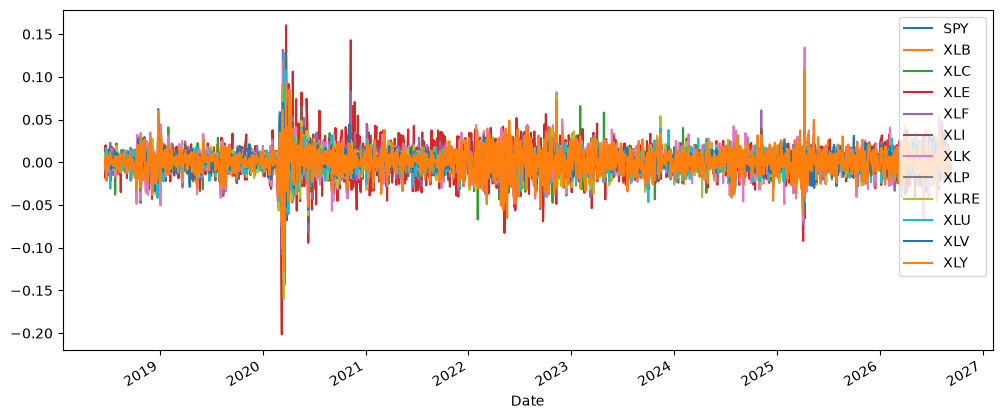

In [ ]:
# 5. Eyeball a plot to catch anything obviously wrong
returns.plot(figsize=(12,5), legend=True)

This set of functions allows us to import data from our set timeline leading up to today. When the initial pull is done it stores the data in a local cache. It then makes sure to only import the data that is not in the local cache already, to minimize the burden on the network. It also redownloads the past 5 days of data and overlaps them with what is in the cache. This ensures that any adjustments in prices are captured. 

### Section 2 - Parameter and Model Uncertainty

#### 2.1 - Simulation Study (no model risk)

In [81]:

# --- Step 0: Ground truth from Section 1 data ---
returns = get_returns()  # from Section 1, simple daily returns, wide format
mu_star = returns.mean().values          # shape (12,)
Sigma_star = returns.cov().values        # shape (12, 12)
tickers = returns.columns.tolist()

n_assets = len(tickers)

# A fixed portfolio weight vector for the Sharpe-ratio diagnostic.
# Equal-weight is a reasonable, simple choice here since the point is to see
# how *estimation noise* propagates into a Sharpe ratio, not to optimize anything.
w_fixed = np.repeat(1 / n_assets, n_assets)

sample_sizes = [63, 126, 252, 504, 1008, 2520]
n_reps = 1000

rng = np.random.default_rng(seed=42)  # reproducibility: fixed seed

scalar_rows = []   # will hold dicts -> DataFrame: n, rep, frobenius_norm, sharpe_hat
long_rows = []      # will hold dicts -> DataFrame: n, rep, ticker, mu_error

for n in sample_sizes:
    for rep in range(n_reps):
        # Draw ONE fresh independent sample of size n from N(mu_star, Sigma_star).
        sample = rng.multivariate_normal(mean=mu_star, cov=Sigma_star, size=n)
        # sample.shape == (n, 12)

        mu_hat = sample.mean(axis=0)                  # shape (12,)
        Sigma_hat = np.cov(sample, rowvar=False)       # shape (12, 12)

        # --- Per-asset mean error (long format) ---
        mu_error = mu_hat - mu_star  # shape (12,)
        for i, ticker in enumerate(tickers):
            long_rows.append({
                "n": n,
                "rep": rep,
                "ticker": ticker,
                "mu_error": mu_error[i]
            })

        # --- Scalar summaries ---
        frob_norm = np.linalg.norm(Sigma_hat - Sigma_star, ord="fro")

        port_return = w_fixed @ mu_hat
        port_vol = np.sqrt(w_fixed @ Sigma_hat @ w_fixed)
        sharpe_hat = port_return / port_vol

        scalar_rows.append({
            "n": n,
            "rep": rep,
            "frobenius_norm": frob_norm,
            "sharpe_hat": sharpe_hat
        })

scalar_df = pd.DataFrame(scalar_rows)
long_df = pd.DataFrame(long_rows)

print(scalar_df.shape)  # expect (6000, 4)
print(long_df.shape)    # expect (72000, 4)
scalar_df.head()

(6000, 4)
(72000, 4)


,n,rep,frobenius_norm,sharpe_hat
0,63,0,0.000330,0.182668
1,63,1,0.000221,-0.019999
2,63,2,0.000752,0.333465
3,63,3,0.000297,-0.015448
4,63,4,0.000196,-0.096244


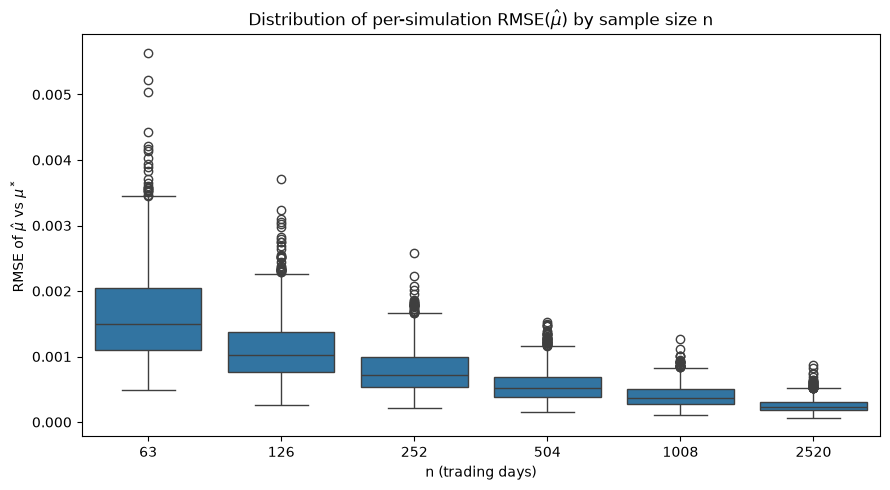

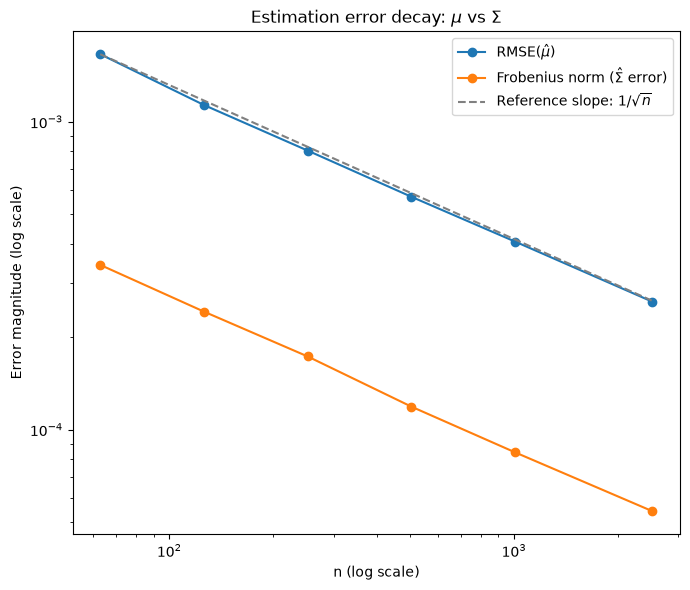

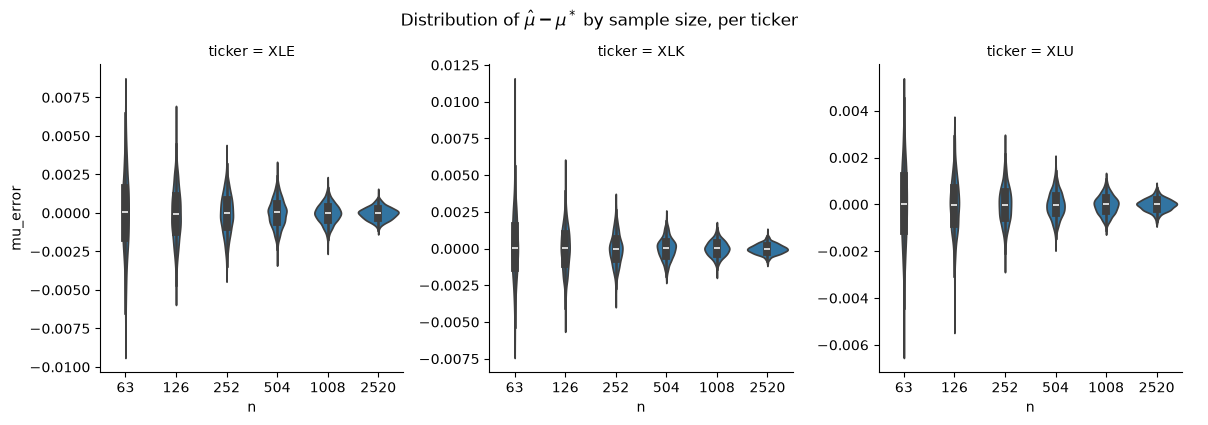

In [82]:

# ---------------------------------------------------------
# Plot 1: Faceted boxplots — per-rep RMSE(mu_hat) across n
# ---------------------------------------------------------
# Reduce the 12-dim per-asset error to one scalar per (n, rep):
# RMSE across assets for that single simulation draw.
rmse_per_rep = (
    long_df
    .groupby(["n", "rep"])["mu_error"]
    .apply(lambda x: np.sqrt(np.mean(x**2)))
    .reset_index(name="rmse_mu")
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=rmse_per_rep, x="n", y="rmse_mu", ax=ax)
ax.set_title("Distribution of per-simulation RMSE($\\hat{\\mu}$) by sample size n")
ax.set_xlabel("n (trading days)")
ax.set_ylabel("RMSE of $\\hat{\\mu}$ vs $\\mu^*$")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Plot 2: Log-log decay of mu error and Sigma error vs n
# ---------------------------------------------------------
summary_by_n = (
    scalar_df.groupby("n")
    .agg(mean_frob=("frobenius_norm", "mean"))
    .reset_index()
)
# bring in mean RMSE(mu) per n from rmse_per_rep
rmse_by_n = rmse_per_rep.groupby("n")["rmse_mu"].mean().reset_index()
summary_by_n = summary_by_n.merge(rmse_by_n, on="n")

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(summary_by_n["n"], summary_by_n["rmse_mu"], marker="o", label="RMSE($\\hat{\\mu}$)")
ax.plot(summary_by_n["n"], summary_by_n["mean_frob"], marker="o", label="Frobenius norm ($\\hat{\\Sigma}$ error)")

# theoretical 1/sqrt(n) reference line, anchored to match the mu curve at the first n
ref_const = summary_by_n["rmse_mu"].iloc[0] * np.sqrt(summary_by_n["n"].iloc[0])
ref_line = ref_const / np.sqrt(summary_by_n["n"])
ax.plot(summary_by_n["n"], ref_line, linestyle="--", color="gray", label="Reference slope: $1/\\sqrt{n}$")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("n (log scale)")
ax.set_ylabel("Error magnitude (log scale)")
ax.set_title("Estimation error decay: $\\mu$ vs $\\Sigma$")
ax.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Plot 3: Faceted violin plots for a few tickers
# ---------------------------------------------------------
tickers_to_show = ["XLK", "XLU", "XLE"]  # pick a growth-y, defensive, and cyclical sector for contrast
subset = long_df[long_df["ticker"].isin(tickers_to_show)]

g = sns.catplot(
    data=subset, x="n", y="mu_error", col="ticker",
    kind="violin", height=4, aspect=1, sharey=False
)
g.fig.suptitle("Distribution of $\\hat{\\mu} - \\mu^*$ by sample size, per ticker", y=1.05)
plt.show()

As the value of n increases we see the variance in the estimates shrink, and the centrality becomes more clear. This is evident in the RMSE of mu_hat vs mu_star: our estimated mu gets much closer to the generating mu value once n gets above 1,000. We can see the errors decay (figure 2) greatly both in terms of RMSE(mu_hat) and the Frobenius Norm (sigma_hat error). This trend can be validated at the individual ticker level as well, where we see massive centralization of the distribution once n breaks 500. I would perhaps make the case here that the higher values are overly centralized: once we get to n = 2,520 we see very little variation in the errors. I am curious if this could cause issues with our modeling down the line, as we estimate a world of over-stability. 

#### 2.2 Model Uncertainty on Real Data

In [ ]:

# ---------------------------------------------------------
# Setup
# ---------------------------------------------------------
sector_tickers = [t for t in returns.columns if t != "SPY"]
market_returns = returns["SPY"].values

# ---------------------------------------------------------
# Approach 1: Sample moments (11 sector ETFs only, matching CAPM's scope)
# ---------------------------------------------------------
mu_sample = returns[sector_tickers].mean()
Sigma_sample = returns[sector_tickers].cov()

# ---------------------------------------------------------
# Approach 2: CAPM (single-factor OLS vs SPY, then law of total
# expectation / covariance to build mu_hat and Sigma_hat)
# ---------------------------------------------------------
def estimate_capm_moments(returns_df, sector_cols, market_col="SPY"):
    market = returns_df[market_col].values
    x_mean = market.mean()
    x_demeaned = market - x_mean
    x_var_sum = np.sum(x_demeaned ** 2)

    alphas, betas, resid_vars = {}, {}, {}
    for ticker in sector_cols:
        y = returns_df[ticker].values
        y_mean = y.mean()
        beta_i = np.sum(x_demeaned * (y - y_mean)) / x_var_sum
        alpha_i = y_mean - beta_i * x_mean
        resid = y - (alpha_i + beta_i * market)
        alphas[ticker] = alpha_i
        betas[ticker] = beta_i
        resid_vars[ticker] = resid.var(ddof=1)

    alpha_s = pd.Series(alphas)
    beta_s = pd.Series(betas)
    resid_var_s = pd.Series(resid_vars)

    market_mean = market.mean()
    market_var = market.var(ddof=1)

    mu_capm = alpha_s + beta_s * market_mean
    beta_vec = beta_s.values.reshape(-1, 1)
    Sigma_capm = (beta_vec @ beta_vec.T) * market_var
    Sigma_capm += np.diag(resid_var_s.values)

    mu_capm = pd.Series(mu_capm.values, index=sector_cols)
    Sigma_capm_df = pd.DataFrame(Sigma_capm, index=sector_cols, columns=sector_cols)
    return mu_capm, Sigma_capm_df


mu_capm, Sigma_capm_df = estimate_capm_moments(returns, sector_tickers, market_col="SPY")

# ---------------------------------------------------------
# Report both full mu vectors and Sigma matrices
# ---------------------------------------------------------
"""print("=== Sample mean vector ===")
print(mu_sample)
print("\n=== CAPM mean vector ===")
print(mu_capm)

print("\n=== Sample covariance matrix ===")
print(Sigma_sample)
print("\n=== CAPM covariance matrix ===")
print(Sigma_capm_df)
"""
# ---------------------------------------------------------
# Compare: mu
# ---------------------------------------------------------
mu_comparison = pd.DataFrame({
    "mu_sample": mu_sample,
    "mu_capm": mu_capm,
    "abs_diff": (mu_sample - mu_capm).abs()
}).sort_values("abs_diff", ascending=False)

print("\n=== Mu comparison (sorted by discrepancy) ===")
print(mu_comparison)

# ---------------------------------------------------------
# Compare: Sigma, via correlation matrices (easier to interpret than raw covariance)
# ---------------------------------------------------------
def cov_to_corr(Sigma):
    d = np.sqrt(np.diag(Sigma))
    return Sigma / np.outer(d, d)

corr_sample = pd.DataFrame(cov_to_corr(Sigma_sample.values), index=sector_tickers, columns=sector_tickers)
corr_capm = pd.DataFrame(cov_to_corr(Sigma_capm_df.values), index=sector_tickers, columns=sector_tickers)

corr_diff = (corr_sample - corr_capm).abs()
print("\n=== Absolute correlation differences (sample vs CAPM) ===")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
corr_diff.round(3)
print(corr_diff)

diff_stacked = corr_diff.where(np.triu(np.ones(corr_diff.shape), k=1).astype(bool)).stack()
print("\n=== Largest correlation discrepancies ===")
print(diff_stacked.sort_values(ascending=False).head(10))



=== Mu comparison (sorted by discrepancy) ===
      mu_sample   mu_capm  abs_diff
XLB    0.000447  0.000447       0.0
XLC    0.000521  0.000521       0.0
XLE    0.000640  0.000640       0.0
XLF    0.000536  0.000536       0.0
XLI    0.000568  0.000568       0.0
XLK    0.000982  0.000982       0.0
XLP    0.000388  0.000388       0.0
XLRE   0.000381  0.000381       0.0
XLU    0.000463  0.000463       0.0
XLV    0.000453  0.000453       0.0
XLY    0.000489  0.000489       0.0

=== Absolute correlation differences (sample vs CAPM) ===
           XLB       XLC           XLE       XLF       XLI           XLK       XLP          XLRE       XLU       XLV           XLY
XLB   0.000000  0.055423  1.555734e-01  0.124036  0.147810  9.685250e-02  0.097897  9.920960e-02  0.092336  0.059267  1.251864e-02
XLC   0.055423  0.000000  7.402770e-02  0.046016  0.078723  5.486168e-03  0.022332  2.987718e-02  0.073694  0.030192  4.419235e-02
XLE   0.155573  0.074028  1.110223e-16  0.190989  0.137288  1.287062e

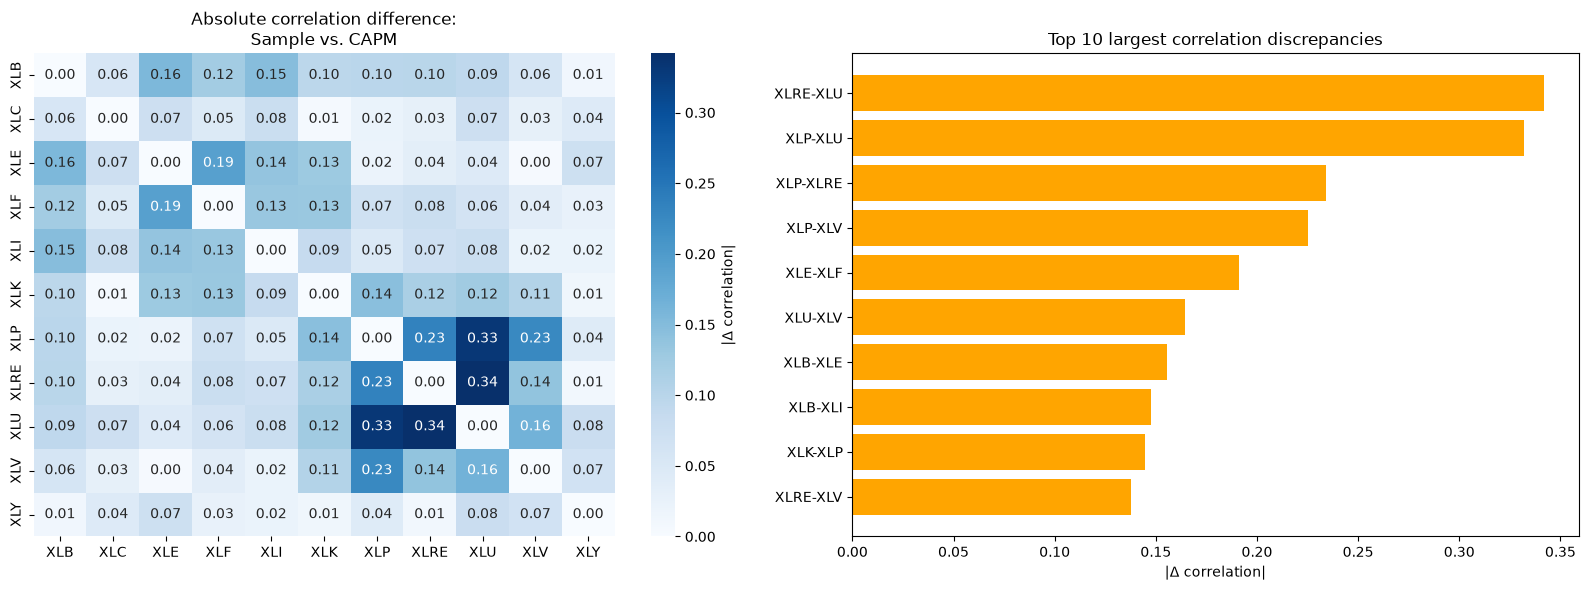

In [ ]:


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Panel 1: full heatmap of correlation differences ---
sns.heatmap(corr_diff, annot=True, fmt=".2f", cmap="Blues",
            vmin=0, ax=axes[0], cbar_kws={"label": "|Δ correlation|"})
axes[0].set_title("Absolute correlation difference:\nSample vs. CAPM")

# --- Panel 2: ranked bar chart of the top discrepancy pairs ---
top_diffs = diff_stacked.sort_values(ascending=False).head(10)
pair_labels = [f"{i}-{j}" for i, j in top_diffs.index]

axes[1].barh(pair_labels[::-1], top_diffs.values[::-1], color="orange")
axes[1].set_xlabel("|Δ correlation|")
axes[1].set_title("Top 10 largest correlation discrepancies")

plt.tight_layout()
plt.show()

When we compare the estimates for mu using the two methods (sample moment vs CAPM) it is clear that the mean values do not vary between estimation methods. This is to be expected, as the OLS approach of CAPM is estimating the mu value based on the same data used to obtain the mu estimation via sample moments. On the other hand, we see a discernable variation in the sigma estimates between the sample moments and CAPM estimation approaches. This suggests that the CAPM method is more sensitive to market fluctuations and does a better job of capturing a larger range of potential outcomes. It is no surprise that CAPM is the industry standard for estimating these parameters. 

#### 2.3 - Boostrap and Rolling Window

##### Bootstrap

In [155]:
n_boot = 1000
n_obs = len(returns)

# Choose a few covariance pairs to track (economically motivated contrast)
pairs_to_track = [("XLK", "XLY"), ("XLU", "XLE"), ("XLF", "XLK")]

boot_mu_rows = []     # long: rep, ticker, mu_hat
boot_sigma_rows = []  # long: rep, pair, sigma_hat

rng = np.random.default_rng(seed=7)

for rep in range(n_boot):
    resample = returns.sample(n=n_obs, replace=True, random_state=rng.integers(1e9))
    mu_hat, Sigma_hat = estimate_capm_moments(resample, sector_tickers,market_col="SPY")

    for ticker in mu_hat.index:
        boot_mu_rows.append({"rep": rep, "ticker": ticker, "mu_hat": mu_hat[ticker]})

    for (t1, t2) in pairs_to_track:
        boot_sigma_rows.append({
            "rep": rep,
            "pair": f"{t1}-{t2}",
            "sigma_hat": Sigma_hat.loc[t1, t2]
        })

boot_mu_df = pd.DataFrame(boot_mu_rows)
boot_sigma_df = pd.DataFrame(boot_sigma_rows)

print(boot_mu_df.shape)     # expect (1000 * 11, 3)
print(boot_sigma_df.shape)  # expect (1000 * 3, 3)

(11000, 3)
(3000, 3)


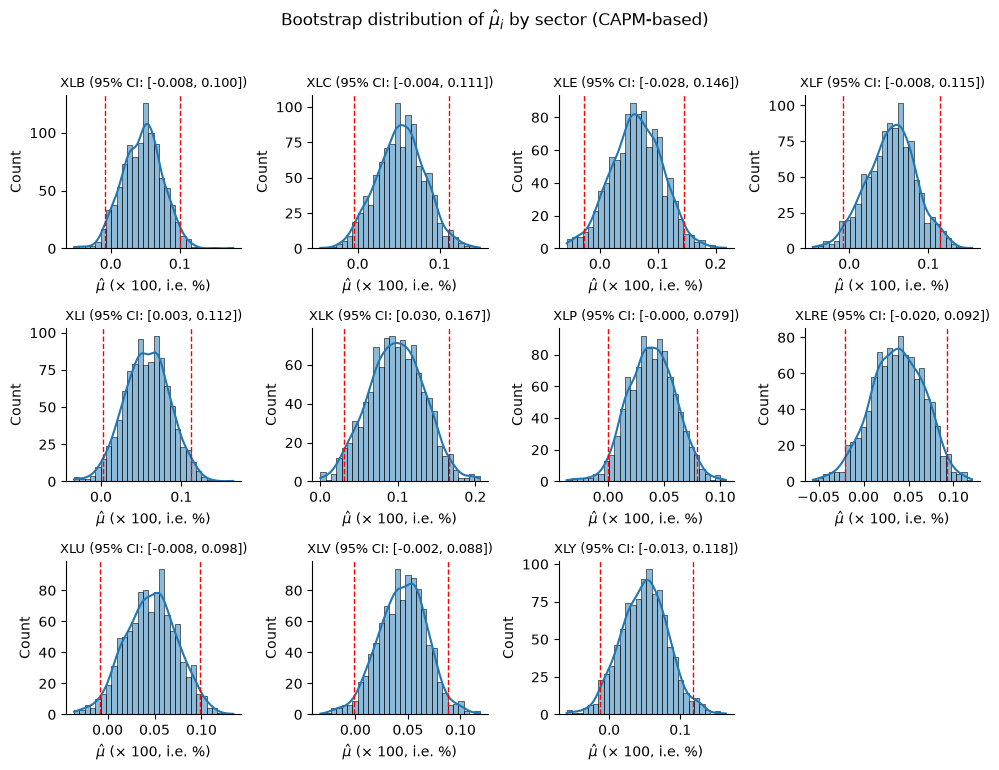

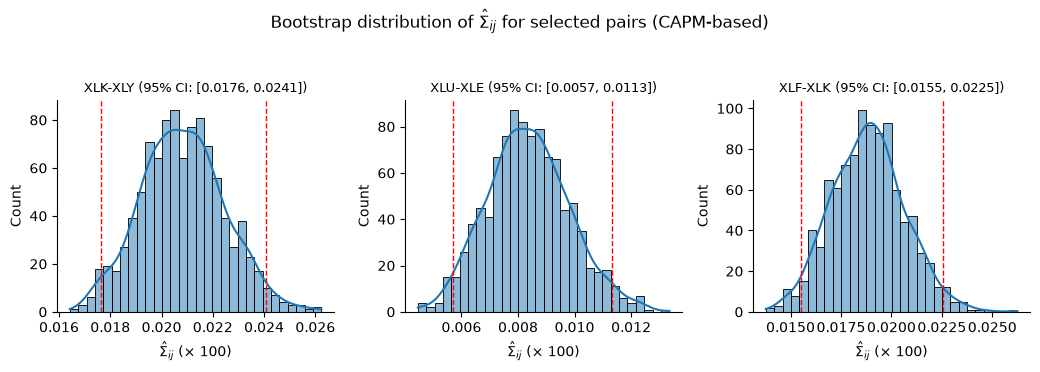

In [ ]:
# ---------------------------------------------------------
# Bootstrap distribution of mu_hat, faceted by ticker,
# with empirical 95% confidence band marked
# ---------------------------------------------------------
boot_mu_df = boot_mu_df.copy()
boot_mu_df["mu_hat_pct"] = boot_mu_df["mu_hat"] * 100  # scale to "percent" units for legibility

tickers_order = sorted(boot_mu_df["ticker"].unique())

g = sns.FacetGrid(boot_mu_df, col="ticker", col_wrap=4, col_order=tickers_order,
                   sharex=False, sharey=False, height=2.5)
g.map(sns.histplot, "mu_hat_pct", kde=True, bins=30)

for ax, ticker in zip(g.axes.flat, tickers_order):
    vals = boot_mu_df.loc[boot_mu_df["ticker"] == ticker, "mu_hat_pct"]
    lo, hi = np.percentile(vals, [2.5, 97.5])
    ax.axvline(lo, color="red", linestyle="--", linewidth=1)
    ax.axvline(hi, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"{ticker} (95% CI: [{lo:.3f}, {hi:.3f}])", fontsize=9)
    ax.set_xlabel("$\\hat{\\mu}$ (× 100, i.e. %)")

g.fig.suptitle("Bootstrap distribution of $\\hat{\\mu}_i$ by sector (CAPM-based)", y=1.02)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Bootstrap distribution of Sigma_hat_ij for tracked pairs
# ---------------------------------------------------------
boot_sigma_df = boot_sigma_df.copy()
boot_sigma_df["sigma_hat_scaled"] = boot_sigma_df["sigma_hat"] * 100  # scale for legibility

g2 = sns.FacetGrid(boot_sigma_df, col="pair", sharex=False, sharey=False, height=3.5)
g2.map(sns.histplot, "sigma_hat_scaled", kde=True, bins=30)

for ax, pair in zip(g2.axes.flat, boot_sigma_df["pair"].unique()):
    vals = boot_sigma_df.loc[boot_sigma_df["pair"] == pair, "sigma_hat_scaled"]
    lo, hi = np.percentile(vals, [2.5, 97.5])
    ax.axvline(lo, color="red", linestyle="--", linewidth=1)
    ax.axvline(hi, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"{pair} (95% CI: [{lo:.4f}, {hi:.4f}])", fontsize=9)
    ax.set_xlabel("$\\hat{\\Sigma}_{ij}$ (× 100)")

g2.fig.suptitle("Bootstrap distribution of $\\hat{\\Sigma}_{ij}$ for selected pairs (CAPM-based)", y=1.05)
plt.tight_layout()
plt.show()

The distributions for mu accross each ticker reveal the nature of our estimations and how they can vary over time. There are a few distributions that actually capture 0.0 within their 95% CI (XLC, XLE, XLF, XLRE, XLU, XLV, XLY). This indicates a risk that our true expected daily return is not positive. This makes perfect sense for the stock market. I do find it interesting that 0.0 falls outside of the 95% CI for any of our tickers. The ones that capture 0.0 are communications, energy, financials, real estate, utilities, health care, and consumer discretionary. With the exception of health care, all of these sectors tend to be sensitive to economic forces, so seeing greater potential for negative or 0.0 values makes sense. And indeed, health care shows the highest lower bound for the CI. 

The selected covariance distribution pairs are natural partners: technology and health care, utilities and energy, financials and technology. Given the nature of these markets I am not shocked to see covariances among them. 

##### Rolling Window

In [157]:
window_size = 252
n_days = len(returns)
n_windows = n_days - window_size + 1

sector_tickers = [t for t in returns.columns if t != "SPY"]

rolling_mu_rows = []      # long: date, ticker, mu_hat
rolling_var_rows = []     # long: date, ticker, variance_hat (diagonal of Sigma)
rolling_pair_rows = []    # long: date, pair, sigma_hat (same pairs as bootstrap, for consistency)

pairs_to_track = [("XLK", "XLY"), ("XLU", "XLE"), ("XLF", "XLK")]

for start in range(n_windows):
    window_data = returns.iloc[start : start + window_size]
    end_date = window_data.index[-1]  # label by the LAST day in the window

    mu_hat, Sigma_hat = estimate_capm_moments(window_data, sector_tickers, market_col="SPY")

    for ticker in mu_hat.index:
        rolling_mu_rows.append({"date": end_date, "ticker": ticker, "mu_hat": mu_hat[ticker]})
        rolling_var_rows.append({"date": end_date, "ticker": ticker, "variance_hat": Sigma_hat.loc[ticker, ticker]})

    for (t1, t2) in pairs_to_track:
        rolling_pair_rows.append({"date": end_date, "pair": f"{t1}-{t2}", "sigma_hat": Sigma_hat.loc[t1, t2]})

rolling_mu_df = pd.DataFrame(rolling_mu_rows)
rolling_var_df = pd.DataFrame(rolling_var_rows)
rolling_pair_df = pd.DataFrame(rolling_pair_rows)

print(rolling_mu_df.shape)     # expect (1813 * 11, 3)
print(rolling_var_df.shape)    # expect (1813 * 11, 3)
print(rolling_pair_df.shape)   # expect (1813 * 3, 3)

(19965, 3)
(19965, 3)
(5445, 3)


##### Plot:

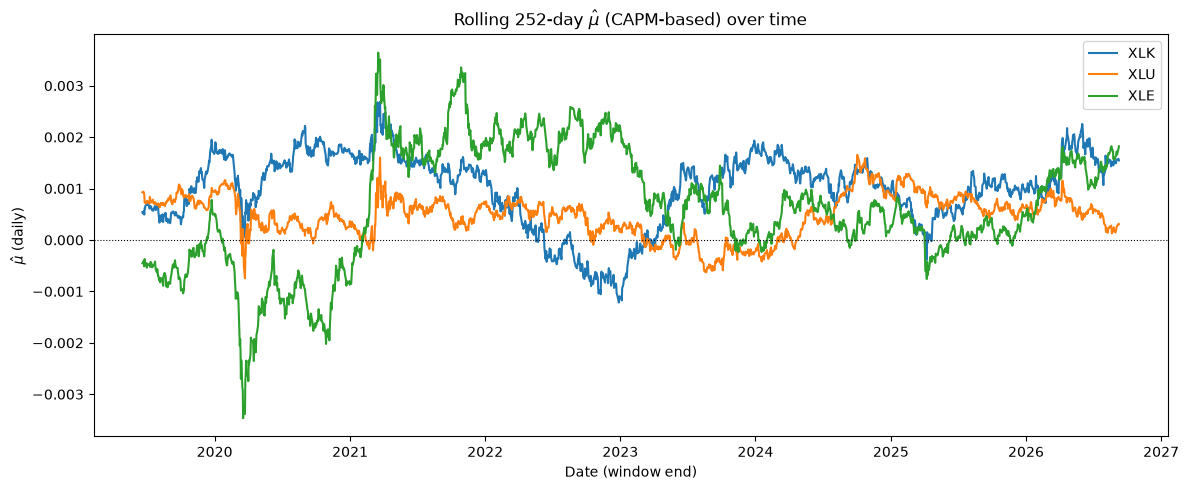

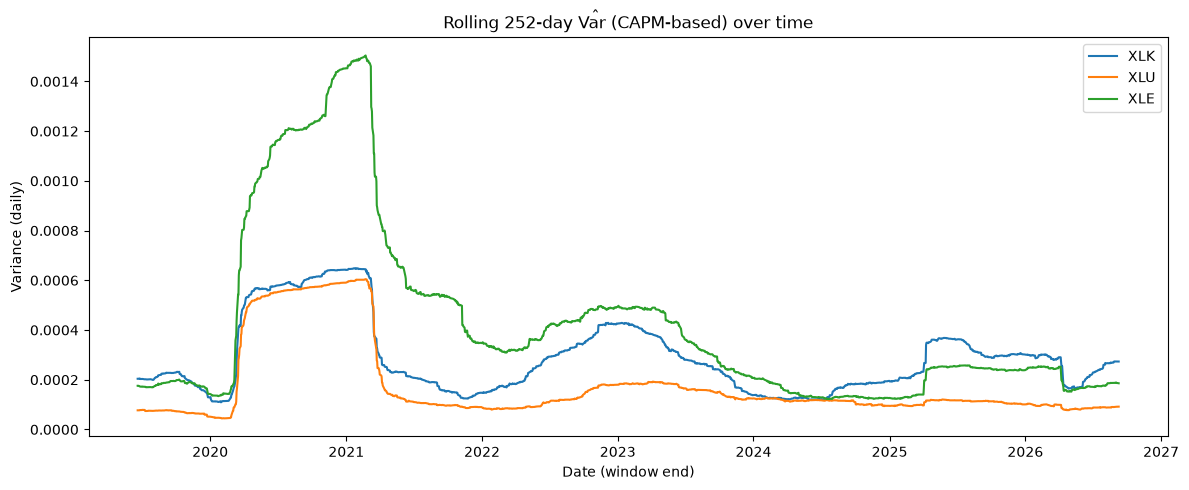

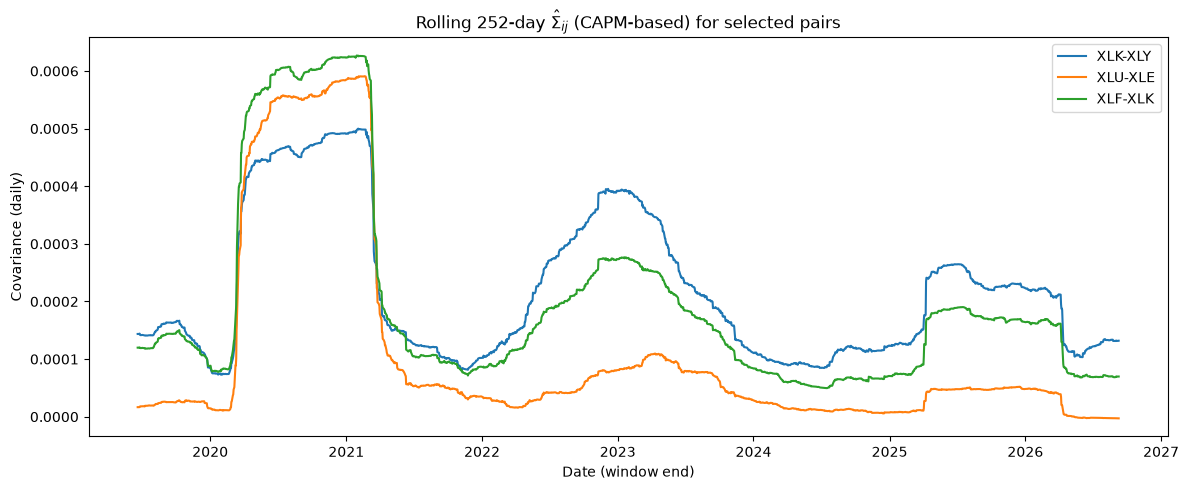

In [158]:

# ---------------------------------------------------------
# Rolling mu_hat over time, for a few sectors
# ---------------------------------------------------------
sectors_to_plot = ["XLK", "XLU", "XLE"]  # growth, defensive, cyclical/energy for contrast

fig, ax = plt.subplots(figsize=(12, 5))
for ticker in sectors_to_plot:
    subset = rolling_mu_df[rolling_mu_df["ticker"] == ticker]
    ax.plot(subset["date"], subset["mu_hat"], label=ticker)

ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax.set_title("Rolling 252-day $\\hat{\\mu}$ (CAPM-based) over time")
ax.set_xlabel("Date (window end)")
ax.set_ylabel("$\\hat{\\mu}$ (daily)")
ax.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Rolling variance (diagonal of Sigma_hat) over time, same sectors
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 5))
for ticker in sectors_to_plot:
    subset = rolling_var_df[rolling_var_df["ticker"] == ticker]
    ax.plot(subset["date"], subset["variance_hat"], label=ticker)

ax.set_title("Rolling 252-day $\\hat{\\text{Var}}$ (CAPM-based) over time")
ax.set_xlabel("Date (window end)")
ax.set_ylabel("Variance (daily)")
ax.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Rolling covariance for tracked pairs over time
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 5))
for pair in rolling_pair_df["pair"].unique():
    subset = rolling_pair_df[rolling_pair_df["pair"] == pair]
    ax.plot(subset["date"], subset["sigma_hat"], label=pair)

ax.set_title("Rolling 252-day $\\hat{\\Sigma}_{ij}$ (CAPM-based) for selected pairs")
ax.set_xlabel("Date (window end)")
ax.set_ylabel("Covariance (daily)")
ax.legend()
plt.tight_layout()
plt.show()

Viewing the rolling 252 day estimates of mu and sigma reveal clear eras, or regimes, in the economic currents. The events of 2020 show a major downturn for utilities, energy, and technology (based on mu estimates). The covariances of technology-discretionary, utilities-enegery, and financials-technology also expose the changes in economic winds over these time periods, and the spikes in covariance reflect the nature of these shocks. 

#### 2.4 - Dimension vs Sample Size

##### Create function to model synthetic ground truth

In [105]:

def build_ground_truth(k, real_betas, real_resid_vars, market_var, market_mean, seed=None):
    """
    Constructs a k-asset ground truth (mu_star_k, Sigma_star_k) using the
    one-factor CAPM structure: Sigma = D + beta beta^T * sigma_m^2.

    For k <= 12, subsets/reuses the real fitted betas/idio-variances directly.
    For k > 12, draws synthetic betas from a Normal fit to the real betas,
    and synthetic idiosyncratic variances from a Log-Normal fit to the real
    idiosyncratic variances (guaranteeing strictly positive values).
    """
    rng = np.random.default_rng(seed)
    n_real = len(real_betas)

    if k <= n_real:
        betas_k = real_betas[:k].copy()
        resid_vars_k = real_resid_vars[:k].copy()
    else:
        # Fit Normal to real betas, sample k fresh synthetic betas
        beta_mean, beta_std = real_betas.mean(), real_betas.std(ddof=1)
        betas_k = rng.normal(loc=beta_mean, scale=beta_std, size=k)

        # Fit Normal to log(real idiosyncratic variances), sample, exponentiate back
        log_resid_vars = np.log(real_resid_vars)
        log_mean, log_std = log_resid_vars.mean(), log_resid_vars.std(ddof=1)
        resid_vars_k = np.exp(rng.normal(loc=log_mean, scale=log_std, size=k))

    # Build Sigma_star(k) = D + beta beta^T * sigma_m^2
    beta_vec = betas_k.reshape(-1, 1)
    Sigma_star_k = (beta_vec @ beta_vec.T) * market_var
    Sigma_star_k += np.diag(resid_vars_k)

    # mu_star(k): reuse the same law-of-total-expectation logic as CAPM.
    # For k <= 12 we could use real alphas; for k > 12 there's no real alpha
    # to subset, so for simplicity and consistency across the whole grid,
    # assume alpha = 0 for all k (i.e., mu_i = beta_i * E[R_M]) -- document this choice.
    
    mu_star_k = betas_k * market_mean

    return mu_star_k, Sigma_star_k, betas_k, resid_vars_k

In [106]:
# test
mu_star_k, sigma_star_k, beta_ser, resid_var_ser = build_ground_truth(150, beta_series, resid_var_series, market_var, market_mean, seed=42)
sigma_star_k.shape  # expect (150, 150)
np.diag(sigma_star_k)  # check that diagonal is positive and reasonable


array([1.98464417e-04, 1.02955927e-04, 1.92977459e-04, 2.31400935e-04,
       9.68544747e-05, 2.32489670e-04, 1.98189713e-04, 2.16139910e-04,
       1.68293522e-04, 1.08319500e-04, 2.14985415e-04, 2.13401600e-04,
       3.39561789e-04, 2.36475122e-04, 2.54214706e-04, 1.13958937e-04,
       2.53433194e-04, 1.51888044e-04, 2.37222587e-04, 1.81118194e-04,
       1.54448986e-04, 1.67731639e-04, 2.53344052e-04, 1.43415752e-04,
       1.27518820e-04, 1.72489456e-04, 3.12321801e-04, 2.14207477e-04,
       2.06758946e-04, 2.23722833e-04, 4.16023238e-04, 1.71541093e-04,
       1.43669455e-04, 1.99183649e-04, 2.42494864e-04, 3.50864378e-04,
       1.86106437e-04, 1.08156600e-04, 1.06257879e-04, 3.26776716e-04,
       3.39993628e-04, 2.13248636e-04, 1.36818949e-04, 2.82928888e-04,
       1.61604331e-04, 1.72416088e-04, 2.71009184e-04, 1.85832604e-04,
       2.28614332e-04, 1.83719809e-04, 2.16933208e-04, 3.04500034e-04,
       1.18951550e-04, 1.96236716e-04, 1.13695483e-04, 1.49201537e-04,
      

##### Run simulation:

In [107]:

k_grid = [5, 12, 50, 150, 252, 400]
n_fixed = 252
n_reps = 200  # fewer reps than before since each rep now involves a k x k matrix inversion, which gets costly at k=400
gamma = 3.0   # fixed risk-aversion parameter


rng = np.random.default_rng(123)

results_rows = []

for k in k_grid:
    mu_star_k, Sigma_star_k, betas_k, resid_vars_k = build_ground_truth(
        k, real_betas=beta_series.values, real_resid_vars=resid_var_series,
        market_var=market_var, market_mean=market_mean, seed=rng.integers(1e9)
    )

    for rep in range(n_reps):
        sample = rng.multivariate_normal(mean=mu_star_k, cov=Sigma_star_k, size=n_fixed)
        mu_hat = sample.mean(axis=0)
        Sigma_hat = np.cov(sample, rowvar=False)

        eigvals = np.linalg.eigvalsh(Sigma_hat)  # eigvalsh: for symmetric matrices, faster & numerically cleaner
        smallest_eig = eigvals.min()
        largest_eig = eigvals.max()
        cond_number = largest_eig / smallest_eig if smallest_eig > 0 else np.inf

        # Use pseudo-inverse to avoid a hard crash when Sigma_hat is exactly singular (k > n case);
        # pinv still lets us observe the "blow-up" numerically rather than erroring out entirely.
        Sigma_hat_inv = np.linalg.pinv(Sigma_hat)
        w_star = (1 / gamma) * Sigma_hat_inv @ mu_hat

        w_norm = np.linalg.norm(w_star, ord=2)
        gross_leverage = np.sum(np.abs(w_star))

        results_rows.append({
            "k": k,
            "rep": rep,
            "smallest_eig": smallest_eig,
            "cond_number": cond_number,
            "w_norm": w_norm,
            "gross_leverage": gross_leverage
        })

results_df = pd.DataFrame(results_rows)
print(results_df.shape)  # expect (6 * 200, 6)
results_df.groupby("k")[["smallest_eig", "cond_number", "w_norm"]].median()

(1200, 6)


,smallest_eig,cond_number,w_norm
k,,,
5,4.355710e-05,1.831808e+01,4.796971e+00
12,2.949537e-05,5.588963e+01,8.304403e+00
50,1.247657e-05,5.808270e+02,2.835128e+01
150,3.005713e-06,6.393904e+03,1.285445e+02
252,2.543381e-21,1.173908e+19,9.580142e+11
400,-3.514706e-18,inf,1.304844e+02


In this exercise I fitted a simple parametric distribution to the 12 real ticker values that I have to work with, and used that as a synthetic data generator to handle instances where k > 12. I converted the values to a log-normal scale before sampling to ensure the sampled values are not negative, then I exponentiated the samples back to non-log scale. This approach allows me to capture synthetic data samples that are similar to our ground truth, while allowing for some realistic indiosyncratic noise, and avoiding accidentally capturing unrealistic negative values. 

Also note that the pseudo inverse was used here in order to avoid the code crashing out when the value of k goes beyond 252.

##### Create plots:

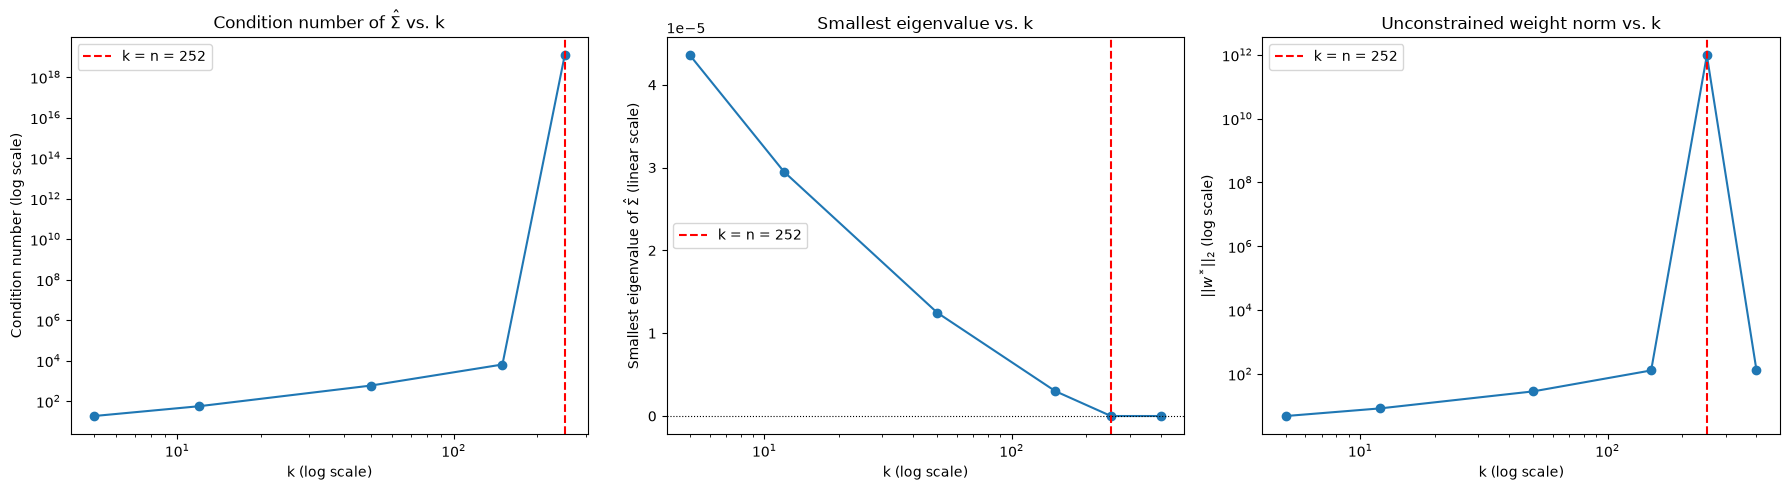

In [108]:

summary_by_k = results_df.groupby("k").median(numeric_only=True).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Panel 1: Condition number vs k ---
axes[0].plot(summary_by_k["k"], summary_by_k["cond_number"], marker="o")
axes[0].axvline(n_fixed, color="red", linestyle="--", label=f"k = n = {n_fixed}")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("k (log scale)")
axes[0].set_ylabel("Condition number (log scale)")
axes[0].set_title("Condition number of $\\hat{\\Sigma}$ vs. k")
axes[0].legend()

# --- Panel 2: Smallest eigenvalue vs k ---
# Note: eigenvalues near/at k=n and beyond can be ~0 or numerically negative,
# which breaks a log scale directly -- plot on linear y-scale to show this honestly,
# including the sign, rather than hiding it with a log transform.
axes[1].plot(summary_by_k["k"], summary_by_k["smallest_eig"], marker="o")
axes[1].axhline(0, color="black", linewidth=0.8, linestyle=":")
axes[1].axvline(n_fixed, color="red", linestyle="--", label=f"k = n = {n_fixed}")
axes[1].set_xscale("log")
axes[1].set_xlabel("k (log scale)")
axes[1].set_ylabel("Smallest eigenvalue of $\\hat{\\Sigma}$ (linear scale)")
axes[1].set_title("Smallest eigenvalue vs. k")
axes[1].legend()

# --- Panel 3: ||w*||_2 (unconstrained weight norm) vs k ---
axes[2].plot(summary_by_k["k"], summary_by_k["w_norm"], marker="o")
axes[2].axvline(n_fixed, color="red", linestyle="--", label=f"k = n = {n_fixed}")
axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_xlabel("k (log scale)")
axes[2].set_ylabel("$||w^*||_2$ (log scale)")
axes[2].set_title("Unconstrained weight norm vs. k")
axes[2].legend()

plt.tight_layout()
plt.show()

These plots illustrate the problem that arises when the value of k goes beyond 252. The sample covariance matrix computed from n observations of k variables is rank-limited to at most n: it cannot have more than n independent directions of variation, not matter how large k is. The eigenvalues collapse to zero: when they are near zero, the inverse blows up to a very large finite number, but when they reach zero, their inverses become undefined due to a divide by zero error. The plots illustrate what happens to the condition number and the smallest eigenvalue of sigma_hat as k passes 252. We also see what happens to the weight vector under these conditions.

### Section 3 - How Uncertainty in Parameters Propagates to Weights 

#### 3.1 - Sensitivity to Gamma

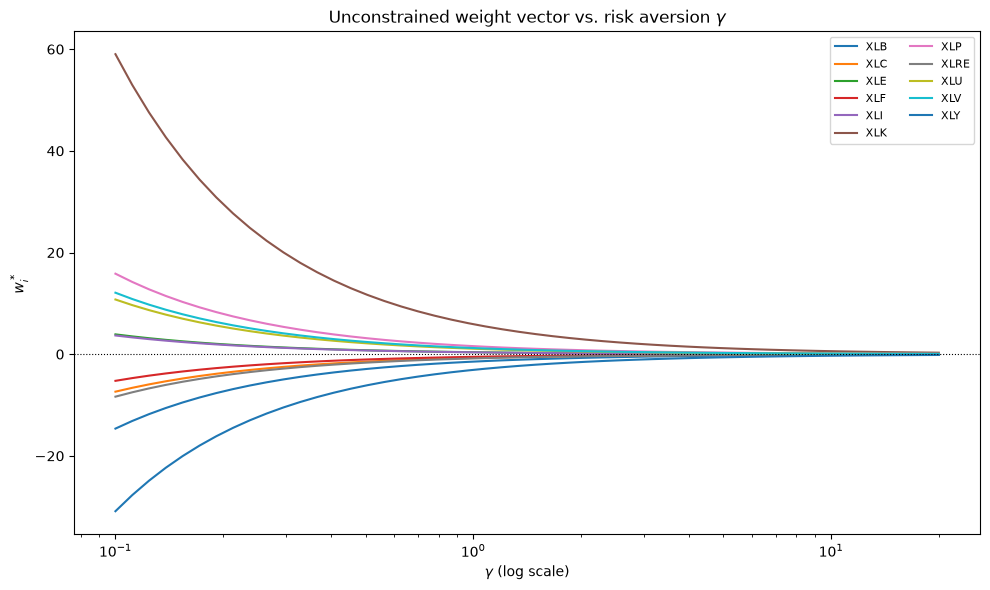

In [109]:

# Fixed base estimate: use your full-sample CAPM mu_hat, Sigma_hat from Section 2.2
# (mu_capm, Sigma_capm_df from earlier in the notebook)
mu_base = mu_capm.values
Sigma_base = Sigma_capm_df.values
tickers_base = mu_capm.index.tolist()

Sigma_base_inv = np.linalg.inv(Sigma_base)
raw_direction = Sigma_base_inv @ mu_base  # this is the fixed vector gamma only rescales

gamma_grid = np.logspace(np.log10(0.1), np.log10(20), 50)  # log-spaced grid from 0.1 to 20

weight_rows = []
for gamma in gamma_grid:
    w_star = (1 / gamma) * raw_direction
    for ticker, w in zip(tickers_base, w_star):
        weight_rows.append({"gamma": gamma, "ticker": ticker, "weight": w})

weights_df = pd.DataFrame(weight_rows)

# --- Plot: each sector's weight as a function of gamma ---
fig, ax = plt.subplots(figsize=(10, 6))
for ticker in tickers_base:
    subset = weights_df[weights_df["ticker"] == ticker]
    ax.plot(subset["gamma"], subset["weight"], label=ticker)

ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax.set_xscale("log")
ax.set_xlabel("$\\gamma$ (log scale)")
ax.set_ylabel("$w^*_i$")
ax.set_title("Unconstrained weight vector vs. risk aversion $\\gamma$")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

As gamma grows we see the weights of all of our tickers start to asymptotically approach zero, albeit coming from different directions. Some tickers get positive weights while others get negative weights for certain risk tollerances. While a "reasonable" allocation is very subjective, there is a strong case to be made for a gamma value between 0.5 and 1 (10^0 on log scale in the plot) since these show a far more balanced portfolio than either of the extremes. 

#### 3.2 Sensitivity to mu

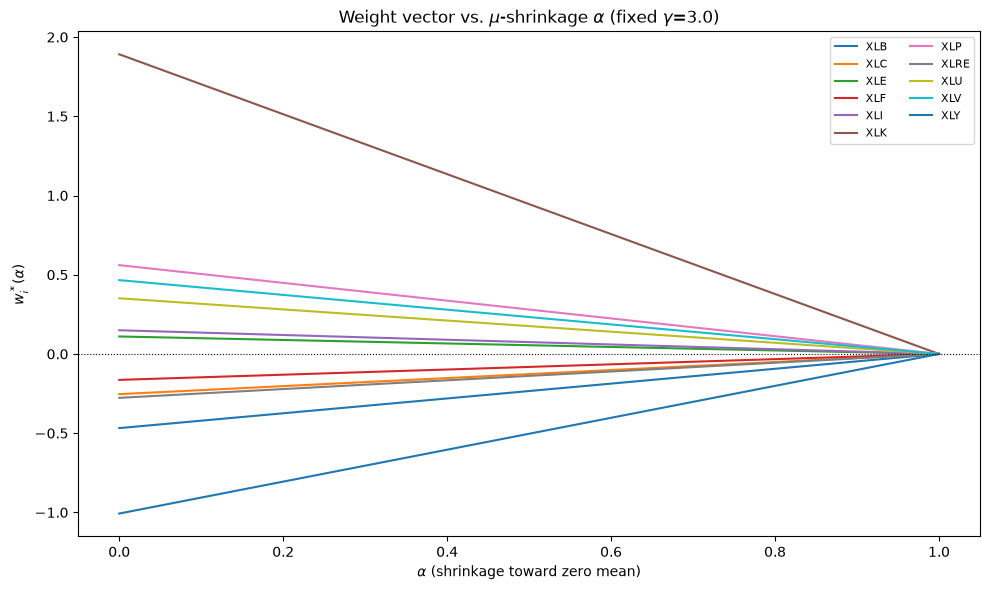

In [22]:
alpha_grid = np.linspace(0, 1, 50)

weight_rows_alpha = []
gamma_fixed = 3.0  # pick a single fixed gamma for this exercise, per the assignment

for alpha in alpha_grid:
    mu_alpha = (1 - alpha) * mu_base
    w_star = (1 / gamma_fixed) * (Sigma_base_inv @ mu_alpha)
    for ticker, w in zip(tickers_base, w_star):
        weight_rows_alpha.append({"alpha": alpha, "ticker": ticker, "weight": w})

weights_alpha_df = pd.DataFrame(weight_rows_alpha)

fig, ax = plt.subplots(figsize=(10, 6))
for ticker in tickers_base:
    subset = weights_alpha_df[weights_alpha_df["ticker"] == ticker]
    ax.plot(subset["alpha"], subset["weight"], label=ticker)

ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax.set_xlabel("$\\alpha$ (shrinkage toward zero mean)")
ax.set_ylabel("$w^*_i(\\alpha)$")
ax.set_title(f"Weight vector vs. $\\mu$-shrinkage $\\alpha$ (fixed $\\gamma$={gamma_fixed})")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

For this exercise a fixed gamma value of 3.0 was used. We see that as alpha grows, it has the effect of shrinking all the weights. This is because alpha is a scalar value being applied to a set weight matrix. We would not expect any fundamental change in the behavior itself from this change - we are just rescalling the weights. The weights seem to decrease linearly towards 0 as alpha grows (and thereby shrinking 1-alpha towards zero). This plot does not seem to tell us very much, or give us a clear idead of where the weights become "well behaved" so I decided to probe this a little furter and try to clarfiy my understanding. The following plots aim to provide more insight to this question. If we look at the phase plot of XLK vs XLU across various values of alpha, we see that at all times a greater weight is being given to XLK than XLU.

In [118]:

def compute_weights_over_knob(knob_name, knob_values, mu_base, Sigma_base_inv,
                                gamma_fixed=3.0, tickers=None):
    """
    Computes w*(knob) for knob_name in {'gamma', 'alpha', 's'}, holding
    everything else fixed. All three reduce to the same underlying operation:
    a scalar rescaling of the fixed direction vector Sigma_base_inv @ mu_base.

    - gamma sweep: w*(gamma) = (1/gamma) * raw_direction
    - alpha sweep: w*(alpha) = (1/gamma_fixed) * (1-alpha) * raw_direction
    - s sweep:     w*(s)     = (1/(gamma_fixed * s**2)) * raw_direction
    """
    raw_direction = Sigma_base_inv @ mu_base
    rows = []

    for val in knob_values:
        if knob_name == "gamma":
            w_star = (1 / val) * raw_direction
        elif knob_name == "alpha":
            w_star = (1 - val) * (1 / gamma_fixed) * raw_direction
        elif knob_name == "s":
            w_star = (1 / (gamma_fixed * val**2)) * raw_direction
        else:
            raise ValueError("knob_name must be 'gamma', 'alpha', or 's'")

        for ticker, w in zip(tickers, w_star):
            rows.append({knob_name: val, "ticker": ticker, "weight": w})

    return pd.DataFrame(rows)


def plot_phase_and_leverage(df, knob_name, tickers, pair_for_phase=("XLK", "XLU"),
                              leverage_threshold=2.0):
    """
    Option A: phase plot of one sector's weight vs another's, parameterized by the knob.
    Option B: gross leverage (sum |w_i|) vs the knob, with a reference threshold line
              marking a chosen 'reasonable leverage' cutoff, and the knob value at
              which the curve crosses that threshold.
    """
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # --- Option A: phase plot ---
    t1, t2 = pair_for_phase
    pivot = df.pivot(index=knob_name, columns="ticker", values="weight")
    axes[0].plot(pivot[t1], pivot[t2], marker="o", markersize=3)
    axes[0].axhline(0, color="gray", linewidth=0.6)
    axes[0].axvline(0, color="gray", linewidth=0.6)
    axes[0].set_xlabel(f"$w^*_{{{t1}}}$")
    axes[0].set_ylabel(f"$w^*_{{{t2}}}$")
    axes[0].set_title(f"Phase plot: {t1} vs {t2} weight, swept over {knob_name}")

    # --- Option B: gross leverage vs knob, with threshold crossing ---
    leverage = (
        df.groupby(knob_name)["weight"]
        .apply(lambda w: np.abs(w).sum())
        .reset_index(name="gross_leverage")
        .sort_values(knob_name)
    )

    axes[1].plot(leverage[knob_name], leverage["gross_leverage"], marker="o")
    axes[1].axhline(leverage_threshold, color="red", linestyle="--",
                     label=f"Leverage = {leverage_threshold}")

    # Find where the curve crosses the threshold via linear interpolation
    # between the two points that straddle it.
    vals = leverage[knob_name].values
    lev = leverage["gross_leverage"].values
    crossing_knob = None
    for i in range(len(lev) - 1):
        if (lev[i] - leverage_threshold) * (lev[i + 1] - leverage_threshold) < 0:
            # crossing occurs between index i and i+1; interpolate
            frac = (leverage_threshold - lev[i]) / (lev[i + 1] - lev[i])
            crossing_knob = vals[i] + frac * (vals[i + 1] - vals[i])
            break

    if crossing_knob is not None:
        axes[1].axvline(crossing_knob, color="red", linestyle=":", alpha=0.7)
        axes[1].annotate(f"{knob_name} \u2248 {crossing_knob:.3f}",
                          xy=(crossing_knob, leverage_threshold),
                          xytext=(10, 10), textcoords="offset points",
                          color="red", fontsize=9)

    if knob_name == "gamma":
        axes[1].set_xscale("log")
        axes[1].set_yscale("log")
    axes[1].set_xlabel(knob_name)
    axes[1].set_ylabel("Gross leverage $\\sum_i |w_i|$")
    axes[1].set_title(f"Gross leverage vs {knob_name}")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    return crossing_knob

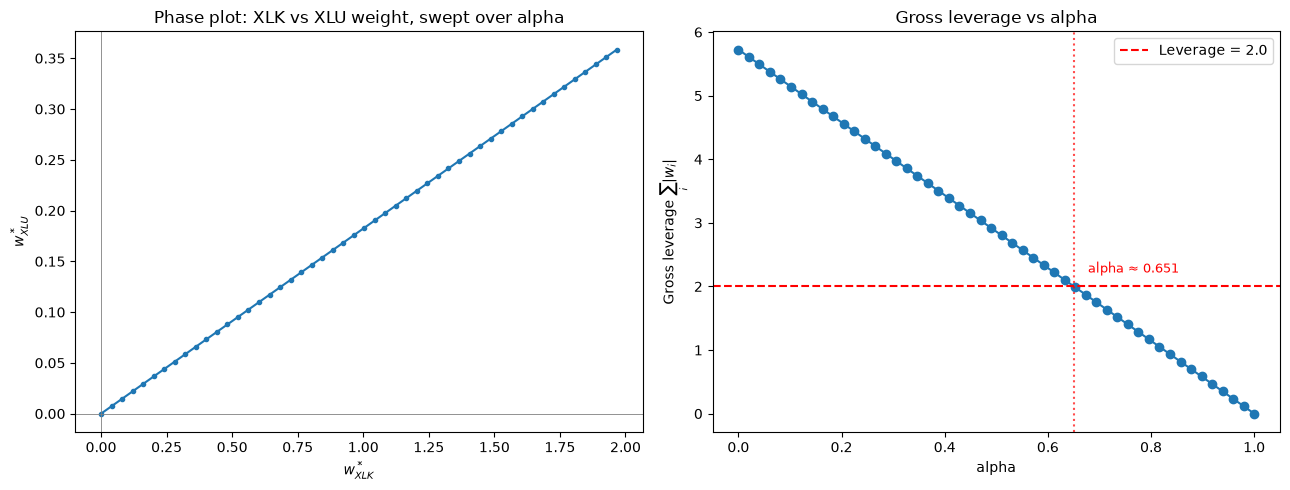

np.float64(0.6507061145176147)

In [122]:
# --- Alpha view ---
alpha_grid = np.linspace(0, 1, 50)
df_alpha = compute_weights_over_knob("alpha", alpha_grid, mu_base, Sigma_base_inv,
                                       gamma_fixed=3.0, tickers=tickers_base)
plot_phase_and_leverage(df_alpha, "alpha", tickers_base)

Alpha essentially dampens our estimates for each ticker and sandbags our final weight matrix. 

#### 3.3 - Sensitivity to Correlations

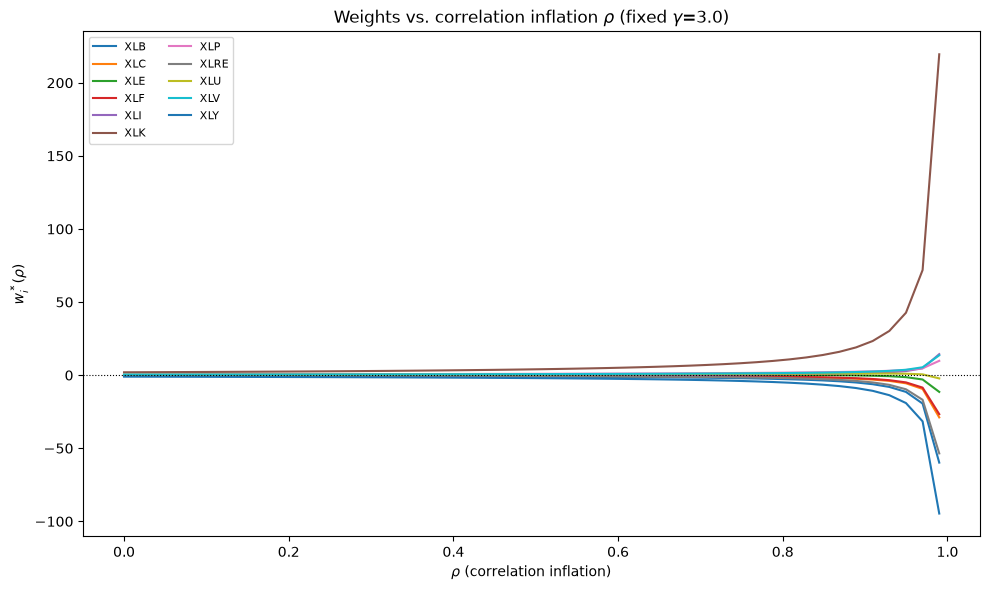

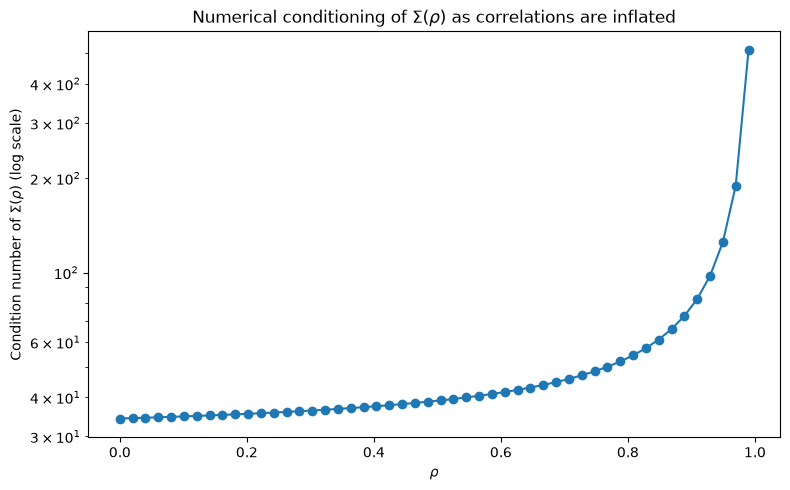

In [123]:

# --- Step 1: decompose Sigma_base into D (std devs) and C (correlation matrix) ---
sigma_vec = np.sqrt(np.diag(Sigma_base))          # standard deviations, shape (k,)
D_inv = np.diag(1 / sigma_vec)                     # diagonal matrix of 1/sigma_i
C_base = D_inv @ Sigma_base @ D_inv                # "undo" the D scaling on both sides

k = len(sigma_vec)
ones_matrix = np.ones((k, k)) / k                  # every entry = 1/k

rho_grid = np.linspace(0, 0.99, 50)  # stop just short of 1, since rho=1 collapses C entirely

weight_rows_rho = []
cond_number_rho = []

D_matrix = np.diag(sigma_vec)  # for reconstructing Sigma(rho) = D C(rho) D

for rho in rho_grid:
    C_rho = (1 - rho) * C_base + rho * ones_matrix
    Sigma_rho = D_matrix @ C_rho @ D_matrix

    # Use pinv defensively, same reasoning as Section 2.4: Sigma(rho) can become
    # near-singular (or worse) as rho -> 1.
    Sigma_rho_inv = np.linalg.pinv(Sigma_rho)
    w_star = (1 / gamma_fixed) * (Sigma_rho_inv @ mu_base)

    eigvals = np.linalg.eigvalsh(Sigma_rho)
    cond_num = eigvals.max() / eigvals.min() if eigvals.min() > 0 else np.inf
    cond_number_rho.append({"rho": rho, "cond_number": cond_num})

    for ticker, w in zip(tickers_base, w_star):
        weight_rows_rho.append({"rho": rho, "ticker": ticker, "weight": w})

weights_rho_df = pd.DataFrame(weight_rows_rho)
cond_rho_df = pd.DataFrame(cond_number_rho)

# --- Plot 1: weights vs rho ---
fig, ax = plt.subplots(figsize=(10, 6))
for ticker in tickers_base:
    subset = weights_rho_df[weights_rho_df["ticker"] == ticker]
    ax.plot(subset["rho"], subset["weight"], label=ticker)
ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax.set_xlabel("$\\rho$ (correlation inflation)")
ax.set_ylabel("$w^*_i(\\rho)$")
ax.set_title(f"Weights vs. correlation inflation $\\rho$ (fixed $\\gamma$={gamma_fixed})")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

# --- Plot 2: condition number vs rho (confirms the near-singularity story) ---
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(cond_rho_df["rho"], cond_rho_df["cond_number"], marker="o")
ax.set_yscale("log")
ax.set_xlabel("$\\rho$")
ax.set_ylabel("Condition number of $\\Sigma(\\rho)$ (log scale)")
ax.set_title("Numerical conditioning of $\\Sigma(\\rho)$ as correlations are inflated")
plt.tight_layout()
plt.show()

As we increase the perturbation (rho) of our correlation matrix we see all the ticker options become more and more correlated. This causes the condition number to blow up, and the weights for each ticket to become extreme. Fundamentally, this perturbation breaks the entire logic of diversification in a portfolio: as assets become more and more correlated with each other, the benefit of optimizing weight allocations is negated and the process becomes useless. Essentially as rho grows, our sigma loses the ability to differentiate between assets, since they all appear strongly  correlated. 

#### 3.4 - Sensitivity to Volatility 

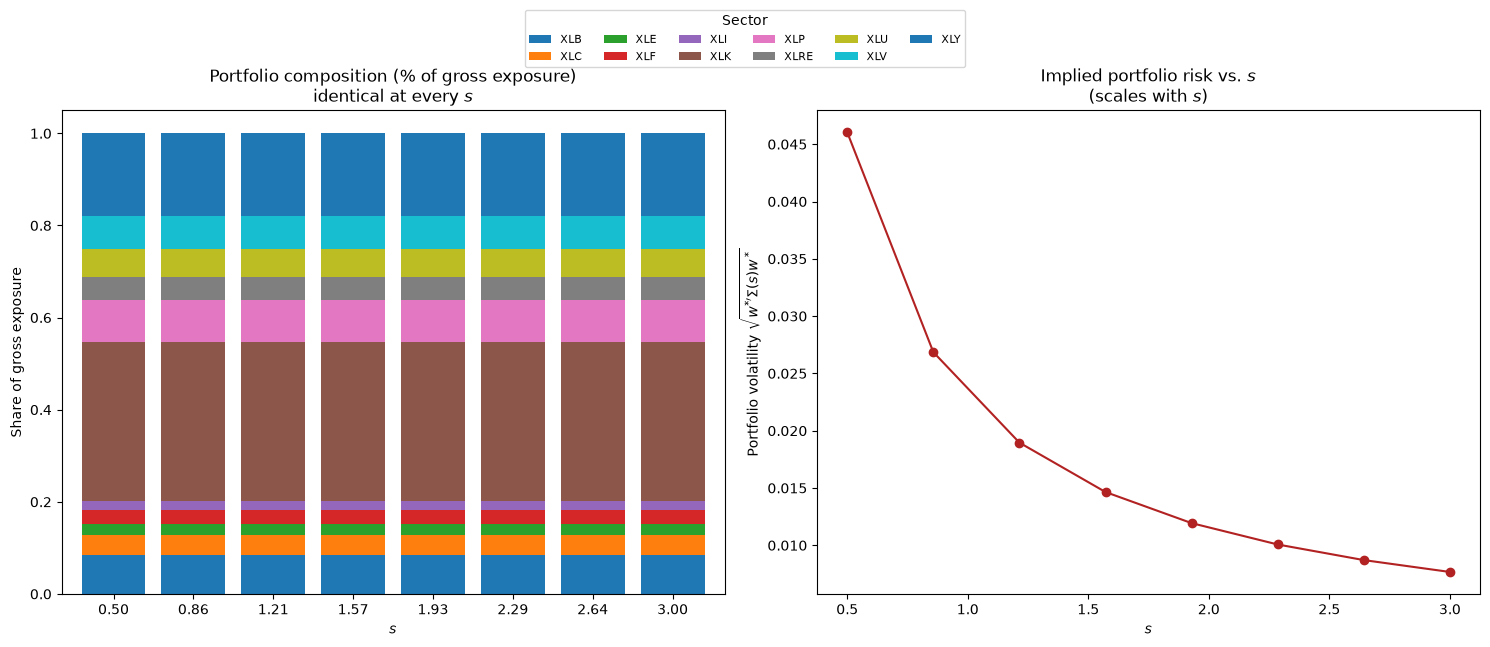

In [128]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

s_grid = np.linspace(0.5, 3, 8)

composition_rows = []
risk_rows = []

for s in s_grid:
    w_s = (1 / (gamma_fixed * s**2)) * raw_direction
    Sigma_s = (s**2) * Sigma_base
    portfolio_vol = np.sqrt(w_s @ Sigma_s @ w_s)

    gross = np.abs(w_s).sum()
    composition_share = np.abs(w_s) / gross

    for ticker, share in zip(tickers_base, composition_share):
        composition_rows.append({"s": s, "ticker": ticker, "share": share})

    risk_rows.append({"s": s, "portfolio_vol": portfolio_vol})

composition_df = pd.DataFrame(composition_rows)
risk_df = pd.DataFrame(risk_rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: stacked bar chart of composition
pivot_comp = composition_df.pivot(index="s", columns="ticker", values="share")
pivot_comp.plot(kind="bar", stacked=True, ax=axes[0], width=0.8, legend=False)
axes[0].set_title("Portfolio composition (% of gross exposure)\nidentical at every $s$")
axes[0].set_xlabel("$s$")
axes[0].set_ylabel("Share of gross exposure")
axes[0].set_xticklabels([f"{s:.2f}" for s in s_grid], rotation=0)

# Panel 2: portfolio volatility vs s
axes[1].plot(risk_df["s"], risk_df["portfolio_vol"], marker="o", color="firebrick")
axes[1].set_title("Implied portfolio risk vs. $s$\n(scales with $s$)")
axes[1].set_xlabel("$s$")
axes[1].set_ylabel("Portfolio volatility $\\sqrt{w^{*\\prime} \\Sigma(s) w^*}$")

# Build the shared legend from panel 1's stacked-bar segments, BEFORE plt.show()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=6, bbox_to_anchor=(0.5, 1.08),
           fontsize=8, title="Sector")

plt.tight_layout()
plt.show()

This is similar to the last one, except now we see that scaling the volatility does not alter the portfolio composition itself, only the implied risk of the overall portfolio. This is the "rising tide lifts all boats" logic that often applies to markets. As the overall market experiences greater volatility, the weights of your portfolio allocation are not going to be able to optimize out of it. It is important to note that this assumes that the volatility is felt consistently across all sectors. 

   sweep  ratio_min   ratio_max   ratio_range
0  gamma   5.381104    5.381104  1.776357e-15
1  alpha   5.486470    5.486470  1.776357e-15
2      s   5.486470    5.486470  1.776357e-15
3    rho -98.490807  132.631306  2.311221e+02


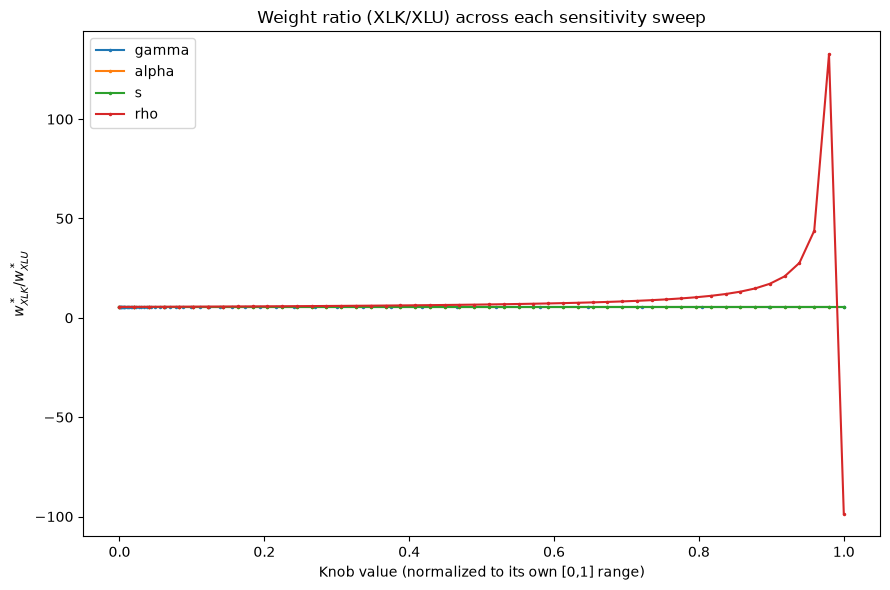

In [ ]:

def weight_ratio_table(df, knob_name, tickers, ratio_pair=("XLK", "XLU")):
    """
    Computes the ratio w_i / w_j at each knob value, to directly check
    whether portfolio COMPOSITION is invariant to this knob.
    """
    t1, t2 = ratio_pair
    pivot = df.pivot(index=knob_name, columns="ticker", values="weight")
    ratio = (pivot[t1] / pivot[t2]).reset_index(name=f"ratio_{t1}_{t2}")
    return ratio

# Compute the same ratio across all four sweeps
ratio_gamma = weight_ratio_table(df_gamma, "gamma", tickers_base)
ratio_alpha = weight_ratio_table(df_alpha, "alpha", tickers_base)
ratio_s = weight_ratio_table(df_s, "s", tickers_base)
ratio_rho = weight_ratio_table(weights_rho_df, "rho", tickers_base)

# --- Summary table: min, max, and range of the ratio under each sweep ---
summary = pd.DataFrame({
    "sweep": ["gamma", "alpha", "s", "rho"],
    "ratio_min": [ratio_gamma.iloc[:, 1].min(), ratio_alpha.iloc[:, 1].min(),
                  ratio_s.iloc[:, 1].min(), ratio_rho.iloc[:, 1].min()],
    "ratio_max": [ratio_gamma.iloc[:, 1].max(), ratio_alpha.iloc[:, 1].max(),
                  ratio_s.iloc[:, 1].max(), ratio_rho.iloc[:, 1].max()],
})
summary["ratio_range"] = summary["ratio_max"] - summary["ratio_min"]
print(summary)

# --- Visual: plot the ratio vs knob for all four sweeps, on normalized [0,1] x-axis ---
fig, ax = plt.subplots(figsize=(9, 6))

for df_ratio, knob_name in [(ratio_gamma, "gamma"), (ratio_alpha, "alpha"),
                             (ratio_s, "s"), (ratio_rho, "rho")]:
    x = df_ratio[knob_name]
    x_norm = (x - x.min()) / (x.max() - x.min())  # normalize each knob's range to [0,1] for comparability
    y = df_ratio.iloc[:, 1]
    ax.plot(x_norm, y, label=knob_name, marker=".", markersize=3)

ax.set_xlabel("Knob value (normalized to its own [0,1] range)")
ax.set_ylabel(f"$w^*_{{XLK}} / w^*_{{XLU}}$")
ax.set_title("Weight ratio (XLK/XLU) across each sensitivity sweep")
ax.legend()
plt.tight_layout()
plt.show()

Bringing it all together: this illustrates the lack of impact from variations in gamma, alpha, and s on the weight ratios beween assets. The only input that impacts the weight ratios is rho, meaning their correlations are being directly impacted. 

### 3.5 - Constrained Weights

In [165]:
def negative_utility(w, mu, Sigma, gamma):
    """
    scipy.optimize.minimize only minimizes, so we minimize the NEGATIVE
    of the utility function to effectively maximize U(w).
    """
    expected_return = w @ mu
    risk_penalty = (gamma / 2) * (w @ Sigma @ w)
    return -(expected_return - risk_penalty)

def utility(w, mu, Sigma, gamma):
    return w @ mu - (gamma / 2) * (w @ Sigma @ w)

k = len(mu_base)

# --- Unconstrained baseline (closed-form) ---
w_unconstrained = (1 / gamma_fixed) * (Sigma_base_inv @ mu_base)

# ---------------------------------------------------------
# Constraint 1: Long-only (w_i >= 0 for all i)
# ---------------------------------------------------------

UTILITY_SCALE = 1e6  # arbitrary positive constant — doesn't change the optimum, just improves SLSQP's numerics

def negative_utility(w, mu, Sigma, gamma):
    return -UTILITY_SCALE * (w @ mu - (gamma / 2) * (w @ Sigma @ w))

w0 = np.repeat(1 / k, k)
bounds_long_only = [(0, None) for _ in range(k)]
constraints_long_only = [{"type": "eq", "fun": lambda w: np.sum(w) - 1}]

result_long_only = minimize(
    negative_utility, w0, args=(mu_base, Sigma_base, gamma_fixed),
    method="SLSQP", bounds=bounds_long_only, constraints=constraints_long_only
)
w_long_only = result_long_only.x

# ---------------------------------------------------------
# Constraint 2: Leverage cap, sum(|w_i|) <= L
# ---------------------------------------------------------
# Not smooth as written (abs value has a kink at 0), so we reformulate:
# split each w_i into a positive part (w_i^+) and negative part (w_i^-),
# where w_i = w_i^+ - w_i^- and |w_i| = w_i^+ + w_i^-, both parts >= 0.

L = 2.0

def negative_utility_split(z, mu, Sigma, gamma, k):
    w_pos, w_neg = z[:k], z[k:]
    w = w_pos - w_neg
    return -(w @ mu - (gamma / 2) * (w @ Sigma @ w))

def leverage_constraint(z, k, L):
    w_pos, w_neg = z[:k], z[k:]
    return L - np.sum(w_pos + w_neg)  # must be >= 0 for SLSQP's inequality convention

# IMPORTANT: initialize from the unconstrained solution (scaled to be feasible if
# needed), NOT from an all-positive equal-weight guess. Starting w_neg at all-zero
# pins the solver at the boundary of "no shorting," and a local solver like SLSQP
# can get stuck there even when shorting would improve the objective.
gross_unconstrained = np.abs(w_unconstrained).sum()
if gross_unconstrained > L:
    w0_leverage = w_unconstrained * (L / gross_unconstrained)
else:
    w0_leverage = w_unconstrained.copy()

z0 = np.concatenate([np.maximum(w0_leverage, 0), np.maximum(-w0_leverage, 0)])
bounds_split = [(0, None) for _ in range(2 * k)]
constraints_leverage = [{"type": "ineq", "fun": leverage_constraint, "args": (k, L)}]

result_leverage = minimize(
    negative_utility_split, z0, args=(mu_base, Sigma_base, gamma_fixed, k),
    method="SLSQP", bounds=bounds_split, constraints=constraints_leverage
)
w_leverage_capped = result_leverage.x[:k] - result_leverage.x[k:]

# ---------------------------------------------------------
# Compare all three
# ---------------------------------------------------------
u_unconstrained = utility(w_unconstrained, mu_base, Sigma_base, gamma_fixed)
u_long_only = utility(w_long_only, mu_base, Sigma_base, gamma_fixed)
u_leverage_capped = utility(w_leverage_capped, mu_base, Sigma_base, gamma_fixed)

comparison_df = pd.DataFrame({
    "ticker": tickers_base,
    "w_unconstrained": w_unconstrained,
    "w_long_only": w_long_only,
    "w_leverage_capped": w_leverage_capped
})

print(comparison_df)
print(f"\nUtility (unconstrained):    {u_unconstrained:.6f}")
print(f"Utility (long-only):        {u_long_only:.6f}  | utility given up: {u_unconstrained - u_long_only:.6f}")
print(f"Utility (leverage-capped):  {u_leverage_capped:.6f}  | utility given up: {u_unconstrained - u_leverage_capped:.6f}")


   ticker  w_unconstrained   w_long_only  w_leverage_capped
0     XLB        -0.487966  0.000000e+00          -0.098170
1     XLC        -0.245780  0.000000e+00          -0.001391
2     XLE         0.129943  4.942093e-10           0.079616
3     XLF        -0.174753  0.000000e+00           0.025694
4     XLI         0.122571  0.000000e+00           0.071137
5     XLK         1.967210  1.000000e+00           0.749429
6     XLP         0.527825  4.545611e-10           0.198202
7    XLRE        -0.278541  0.000000e+00          -0.035694
8     XLU         0.358557  5.936396e-10           0.145177
9     XLV         0.403033  2.616281e-10           0.159883
10    XLY        -1.029659  0.000000e+00          -0.280659

Utility (unconstrained):    0.000795
Utility (long-only):        0.000556  | utility given up: 0.000239
Utility (leverage-capped):  0.000589  | utility given up: 0.000206


In [161]:
print(result_long_only.success, result_long_only.message, result_long_only.nit)

True Optimization terminated successfully 1


Here we apply realistic constraints to our weight values. When there are no constraints at all, we see a greater generation of utility across the portfolio. Applying a long-only rule to the weights results in all the previously shorted assets being bounded at zero weight rather than investing in them at all. This result is logical given the constraints and waht the optimization determined to be the best path previously with unconstrained. The long-only constraint results in a degraded utility performance for the portfolio. When we apply a leverage limit to our portfolio we also see a degredation in utility overall. Thhe unconstrained portfolio generates the most utility, followed by the leverage-capped one, and finally the long-only portfolio generates the lowest utility. 

### Section 4 - The Effect of Rebalancing and Trading Costs

In [180]:
# ============================================================
# Section 4 setup: train/test split + w* on TRAIN ONLY
# ============================================================
# Uses `returns` and `estimate_capm_moments` from earlier sections.
# Deliberately uses fresh variable names so nothing Section 5 relies on is touched.

sector_cols = [c for c in returns.columns if c != "SPY"]

split_idx = int(len(returns) * 0.6)
train_returns = returns.iloc[:split_idx]
test_returns  = returns.iloc[split_idx:]

# --- Model weights: closed-form unconstrained MVO, TRAIN ONLY, then normalized ---
# w* = (1/gamma) * Sigma^-1 mu, then scaled to sum to 1 (fully invested).
# No solver here on purpose -> no SLSQP stalling. Normalizing makes the backtest
# a clean $1 portfolio, so turnover and cost read as fractions of capital.
# (Because we normalize, gamma cancels out of the *composition* -- fine for Section 4.)
gamma_backtest = 3.0
mu_hat_train, Sigma_hat_train = estimate_capm_moments(train_returns, sector_cols, market_col="SPY")

raw_direction = np.linalg.solve(Sigma_hat_train.values, mu_hat_train.values)
w_star_train  = raw_direction / raw_direction.sum()
w_star_train  = pd.Series(w_star_train, index=sector_cols)

print("Weights sum to:", w_star_train.sum().round(6),
      "| gross leverage:", np.abs(w_star_train.values).sum().round(3))
print(w_star_train.round(4))

# --- Shared performance metric helper (used by 4.1 and 4.2) ---
def performance_metrics(daily_returns, risk_free_daily=0.0, periods_per_year=252):
    mean_ret = daily_returns.mean()
    vol      = daily_returns.std(ddof=1)
    cumulative = (1 + daily_returns).cumprod()
    drawdown   = (cumulative - cumulative.cummax()) / cumulative.cummax()
    return {
        "annualized_return": cumulative.iloc[-1] ** (periods_per_year / len(daily_returns)) - 1,
        "annualized_vol":    vol * np.sqrt(periods_per_year),
        "annualized_sharpe": (mean_ret - risk_free_daily) / vol * np.sqrt(periods_per_year),
        "max_drawdown":      drawdown.min(),
        "cumulative_return": cumulative.iloc[-1] - 1,
    }, cumulative

Weights sum to: 1.0 | gross leverage: 6.536
XLB    -0.2219
XLC    -0.7691
XLE    -0.0153
XLF    -0.5633
XLI    -0.3079
XLK     1.7953
XLP     0.9151
XLRE   -0.1961
XLU     0.2476
XLV     0.8099
XLY    -0.6944
dtype: float64


#### 4.1 - Frictionless Rebalancing

              annualized_return  annualized_vol  annualized_sharpe  max_drawdown  cumulative_return
Model (w*)               0.2044          0.3050             0.7624       -0.3910             0.8411
Equal-Weight             0.1649          0.1217             1.3149       -0.1530             0.6503
SPY                      0.2154          0.1497             1.3780       -0.1876             0.8967


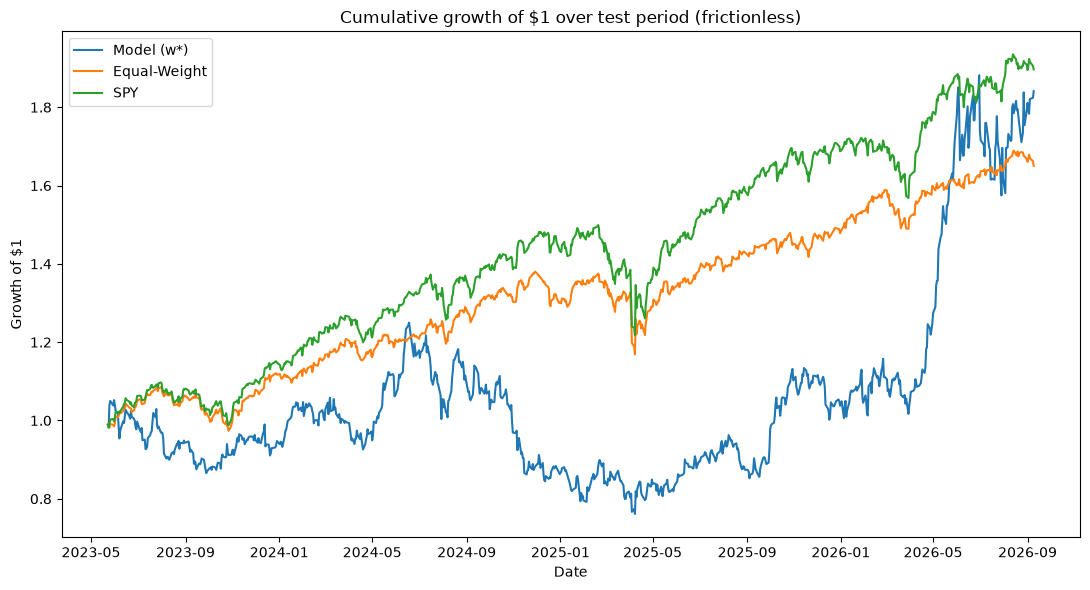

In [181]:
# ============================================================
# 4.1 Frictionless: hold w* constant over the test period (daily rebalance, zero cost)
# ============================================================
model_daily = test_returns[sector_cols] @ w_star_train.values           # w* held constant
ew_daily    = test_returns[sector_cols].mean(axis=1)                     # equal-weight benchmark
spy_daily   = test_returns["SPY"]                                        # SPY benchmark

model_m, model_cum = performance_metrics(model_daily)
ew_m,    ew_cum    = performance_metrics(ew_daily)
spy_m,   spy_cum   = performance_metrics(spy_daily)

summary_table = pd.DataFrame({"Model (w*)": model_m, "Equal-Weight": ew_m, "SPY": spy_m}).T
print(summary_table.round(4))

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(model_cum.index, model_cum.values, label="Model (w*)")
ax.plot(ew_cum.index,    ew_cum.values,    label="Equal-Weight")
ax.plot(spy_cum.index,   spy_cum.values,   label="SPY")
ax.set_title("Cumulative growth of $1 over test period (frictionless)")
ax.set_xlabel("Date"); ax.set_ylabel("Growth of $1"); ax.legend()
plt.tight_layout(); plt.show()

Using a frictionless rebalancing (which is not realistic) we see that our weights are able to outperform both benchmarks over time. This approach does however also result in markedly high volatility over time. 

#### 4.2 - Introducing Transaction Costs

In [182]:
# ============================================================
# 4.2 Transaction cost model
# ============================================================
# NOTE: is_rebalance_day is also used by Section 5's loop -- keep it defined here, unchanged.

def is_rebalance_day(dates, frequency):
    """True on the first trading day of each new period ('daily' => every day)."""
    dates = pd.DatetimeIndex(dates)
    if frequency == "daily":
        return np.ones(len(dates), dtype=bool)
    if frequency == "weekly":
        period_id = dates.isocalendar().week.values + dates.isocalendar().year.values * 100
    elif frequency == "monthly":
        period_id = dates.month.values + dates.year.values * 100
    elif frequency == "quarterly":
        period_id = dates.quarter.values + dates.year.values * 100
    else:
        raise ValueError("frequency must be daily, weekly, monthly, or quarterly")
    return np.concatenate([[True], period_id[1:] != period_id[:-1]])


def backtest_with_costs(test_returns, w_target, sector_cols, frequency, cost_bps, fee_bps):
    """
    Hold w_target, rebalancing at `frequency`. On each rebalance day, turnover is measured
    against the drifted weights, cost = turnover * cost_rate is deducted from portfolio value
    BEFORE the next return compounds. A daily fee haircut (fee_bps annualized) is also applied.
    Returns a Series of NET daily portfolio returns (day 0 = 0, the entry day).
    """
    w_target  = np.asarray(w_target, dtype=float)
    cost_rate = cost_bps / 10000.0
    fee_daily = (fee_bps / 10000.0) / 252.0

    dates = test_returns.index
    rebal = is_rebalance_day(dates, frequency)
    R = test_returns[sector_cols].values

    positions  = w_target.copy()      # portfolio value starts at sum(w_target) = 1
    prev_value = positions.sum()
    net = np.full(len(dates), np.nan)
    net[0] = 0.0                       # entry day: position established, no return yet

    for t in range(1, len(dates)):
        positions    = positions * (1.0 + R[t])       # drift with today's returns
        value_before = positions.sum()
        drifted      = positions / value_before
        if rebal[t]:
            turnover    = np.sum(np.abs(w_target - drifted))
            value_after = value_before * (1.0 - turnover * cost_rate)
            positions   = w_target * value_after       # reset to target
        else:
            value_after = value_before
        net[t]     = (value_after / prev_value - 1.0) - fee_daily
        prev_value = value_after

    return pd.Series(net, index=dates)


# --- Sanity check: daily rebalance, zero cost, zero fee must match 4.1 frictionless ---
check = backtest_with_costs(test_returns, w_star_train.values, sector_cols, "daily", 0, 0)
print("Max abs diff vs frictionless:",
      np.abs(check.iloc[1:].values - model_daily.iloc[1:].values).max())

Max abs diff vs frictionless: 1.2073675392798577e-15


cost_bps      1      5      10     20
frequency                            
daily      0.766  0.735  0.696  0.617
weekly     0.799  0.785  0.767  0.732
monthly    0.772  0.765  0.756  0.738
quarterly  0.780  0.776  0.771  0.762


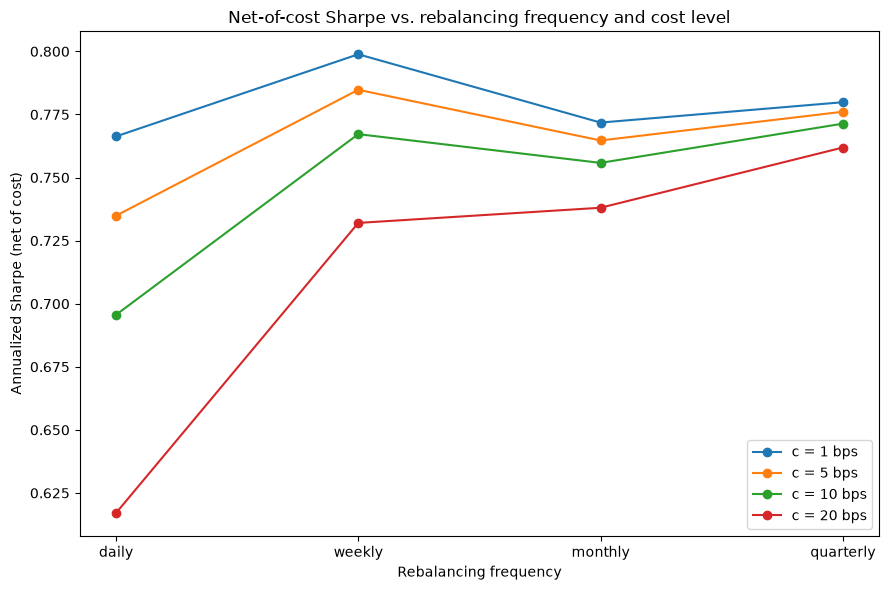

In [183]:
# ============================================================
# 4.2 Sweep: net-of-cost Sharpe vs rebalancing frequency and cost level
# ============================================================
frequencies     = ["daily", "weekly", "monthly", "quarterly"]
cost_levels_bps = [1, 5, 10, 20]
fee_bps         = 0   # set >0 to include a management fee haircut

sweep_rows = []
for freq in frequencies:
    for c in cost_levels_bps:
        nr = backtest_with_costs(test_returns, w_star_train.values, sector_cols, freq, c, fee_bps)
        m, _ = performance_metrics(nr.iloc[1:])   # drop the day-0 entry zero
        sweep_rows.append({"frequency": freq, "cost_bps": c,
                           "sharpe": m["annualized_sharpe"],
                           "max_drawdown": m["max_drawdown"],
                           "annualized_vol": m["annualized_vol"]})

sweep_df = pd.DataFrame(sweep_rows)
print(sweep_df.pivot(index="frequency", columns="cost_bps", values="sharpe").loc[frequencies].round(3))

fig, ax = plt.subplots(figsize=(9, 6))
for c in cost_levels_bps:
    sub = sweep_df[sweep_df["cost_bps"] == c].set_index("frequency").loc[frequencies]
    ax.plot(frequencies, sub["sharpe"], marker="o", label=f"c = {c} bps")
ax.set_xlabel("Rebalancing frequency")
ax.set_ylabel("Annualized Sharpe (net of cost)")
ax.set_title("Net-of-cost Sharpe vs. rebalancing frequency and cost level")
ax.legend(); plt.tight_layout(); plt.show()

This plot makes it clear that the best Sharpe ratio is achieved via weekly rebalancing for c values less than 10. If the cost level is greater than 10 bps, then the optimal Sharpe ratio comes under quarterly rebalancing. The variance in Sharpe ratio between each cost level decreases greatly as the rebalance duration becomes longer. So the optimal rebalance cadence does depend on what the cost level is (c). 

                         annualized_return  annualized_vol  annualized_sharpe  max_drawdown  cumulative_return
Strategy (weekly, 5bps)             0.2122          0.3042             0.7848       -0.3920             0.8790
Equal-Weight                        0.1649          0.1217             1.3149       -0.1530             0.6503
SPY                                 0.2154          0.1497             1.3780       -0.1876             0.8967


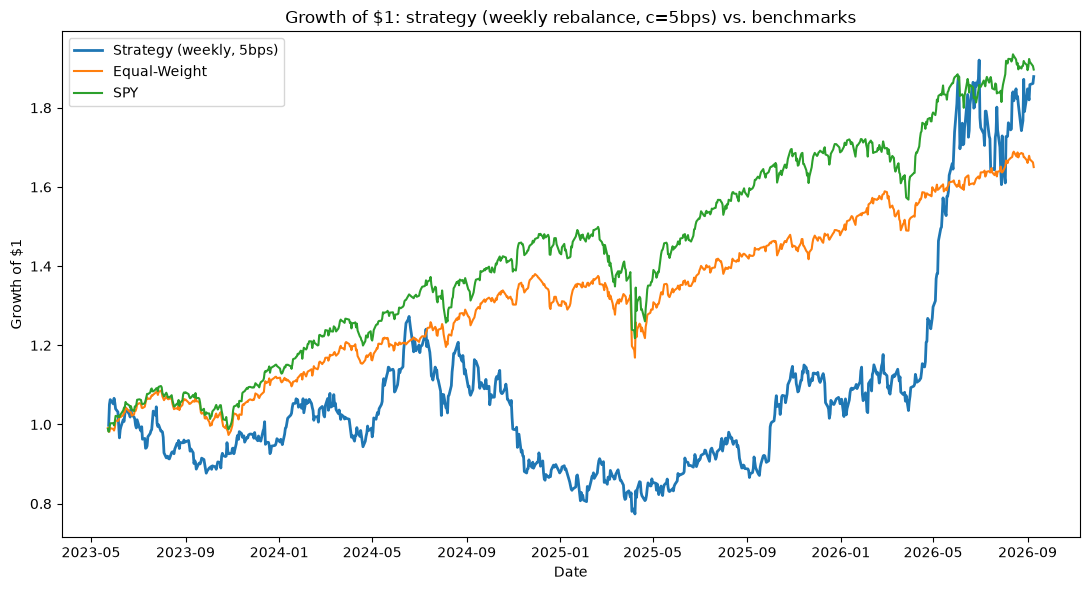

In [199]:
# ============================================================
# 4.2 Strategy (weekly, c=5bps) vs. benchmarks
# ============================================================
strat_r = backtest_with_costs(test_returns, w_star_train.values, sector_cols,
                              frequency="weekly", cost_bps=5, fee_bps=0)

strat_m, strat_cum = performance_metrics(strat_r.iloc[1:])   # drop day-0 entry zero
ew_m,    ew_cum    = performance_metrics(ew_daily)
spy_m,   spy_cum   = performance_metrics(spy_daily)

# --- metrics table ---
summary = pd.DataFrame({
    "Strategy (weekly, 5bps)": strat_m,
    "Equal-Weight":            ew_m,
    "SPY":                     spy_m,
}).T
print(summary.round(4))

# --- growth of $1 ---
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(strat_cum.index, strat_cum.values, label="Strategy (weekly, 5bps)", linewidth=2)
ax.plot(ew_cum.index,    ew_cum.values,    label="Equal-Weight")
ax.plot(spy_cum.index,   spy_cum.values,   label="SPY")
ax.set_title("Growth of $1: strategy (weekly rebalance, c=5bps) vs. benchmarks")
ax.set_xlabel("Date"); ax.set_ylabel("Growth of $1"); ax.legend()
plt.tight_layout(); plt.show()

Using c = 5bps with weekly rebalancing we see our strategy still perform well against the benchmarks. It falls short of the SPY over time, but manages to outperform the equal-weight models. We also see the prolonged period of high vol persist with our strategy. This period of underperformance is a consistent nuance of our strategy. 

### Section 5 - Full Backtester

#### 5.1 - The Loop

In [196]:
# ============================================================
# 5.1 Walk-forward backtest
# ============================================================
# Reuses estimate_capm_moments (Sec 2) and is_rebalance_day (Sec 4).
# Weights: closed-form MVO normalized to fully invested -- same as Section 4,
# so no solver and no stalling. Fit is refreshed only on rebalance days.
#
# Anti-lookahead: at loop step t we fit on returns.iloc[:t+1] (data through day t)
# and earn returns.iloc[t+1] (day t+1). Fit data strictly precedes the return earned.

def solve_long_only_weights(mu, Sigma, gamma, k, w0=None, utility_scale=1e6):
    """Long-only, fully-invested MVO: max w'mu - (gamma/2) w'Sigma w  s.t. w>=0, sum(w)=1.
       utility_scale rescales the objective so SLSQP doesn't stall on tiny daily-return values."""
    if w0 is None:
        w0 = np.repeat(1 / k, k)

    def neg_util(w):
        return -utility_scale * (w @ mu - (gamma / 2) * (w @ Sigma @ w))

    bounds = [(0, None)] * k
    constraints = [{"type": "eq", "fun": lambda w: np.sum(w) - 1}]
    res = minimize(neg_util, w0, method="SLSQP", bounds=bounds, constraints=constraints)
    return res.x

def walk_forward_backtest(returns, sector_cols, gamma=3.0, T0=252,
                          cost_bps=10, fee_bps=5, rebalance_freq="monthly", window=None):
    """
    window=None -> expanding window; window=int -> rolling window of that length.
    Returns a DataFrame indexed by date with columns: r_net, turnover, cost, w_<ticker>.
    """
    dates = returns.index
    T = len(returns)
    R = returns[sector_cols].values
    rebal = is_rebalance_day(dates, rebalance_freq)
    cost_rate = cost_bps / 10000.0
    fee_daily = (fee_bps / 10000.0) / 252.0

    positions = None          # dollar positions per asset (portfolio value = sum)
    w_target  = None
    records   = []

    for t in range(T0, T - 1):
        # --- 1-2. Fit + optimize (only when we'll actually trade, i.e. rebalance days) ---
        if rebal[t] or positions is None:
            wd = returns.iloc[:t + 1] if window is None else returns.iloc[max(0, t + 1 - window):t + 1]
            mu_hat, Sigma_hat = estimate_capm_moments(wd, sector_cols, market_col="SPY")
            raw = np.linalg.solve(Sigma_hat.values, mu_hat.values)   # Sigma^-1 mu
            w_new = solve_long_only_weights(mu_hat.values, Sigma_hat.values, gamma, len(sector_cols))
            #w_new = raw / raw.sum()                                  # normalize to fully invested

        # --- establish portfolio on the first active day ---
        if positions is None:
            positions = w_new.copy()
            w_target  = w_new.copy()
            turnover, cost, value_after = 0.0, 0.0, positions.sum()
        else:
            value_before = positions.sum()
            drifted = positions / value_before
            # --- 3. Trade on rebalance days: cost charged before next return ---
            if rebal[t]:
                turnover    = np.sum(np.abs(w_new - drifted))
                cost        = turnover * cost_rate
                value_after = value_before * (1 - cost)
                positions   = w_new * value_after
                w_target    = w_new.copy()
            else:
                turnover, cost, value_after = 0.0, 0.0, value_before

        # --- 4. Evolve: apply day t+1 returns ---
        positions = positions * (1 + R[t + 1])
        value_new = positions.sum()

        # --- 5. Record ---
        r_net = (value_new / value_after - 1) - fee_daily
        records.append({
            "date": dates[t + 1], "r_net": r_net, "turnover": turnover, "cost": cost,
            **{f"w_{tk}": w for tk, w in zip(sector_cols, w_target)}
        })

    return pd.DataFrame(records).set_index("date")


walk_forward_results = walk_forward_backtest(
    returns, sector_cols, gamma=3.0, T0=252,
    cost_bps=10, fee_bps=5, rebalance_freq="monthly", window=252
)
print(walk_forward_results.shape)
print(walk_forward_results[["r_net", "turnover", "cost"]].describe())

(1813, 14)
             r_net     turnover         cost
count  1813.000000  1813.000000  1813.000000
mean      0.000832     0.032026     0.000032
std       0.015545     0.195571     0.000196
min      -0.138141     0.000000     0.000000
25%      -0.006169     0.000000     0.000000
50%       0.001244     0.000000     0.000000
75%       0.008549     0.000000     0.000000
max       0.117317     2.000000     0.002000


This backtest was built with the option to use an expanding window or use a fixed-length rolling window. I decided to use the 252 day rolling window for my application. I want my system to be able to capture market changes over time and not get bogged down on financial data from years past. 

#### 5.2 - Performance Report Tearsheet

              annualized_return  annualized_vol  annualized_sharpe  max_drawdown  ann_turnover  total_cost_%cap
Strategy                 0.1961          0.2468             0.8500       -0.3116        8.0705           0.0581
Equal-Weight             0.1303          0.1854             0.7543       -0.3634           NaN              NaN
SPY                      0.1579          0.1964             0.8453       -0.3372           NaN              NaN


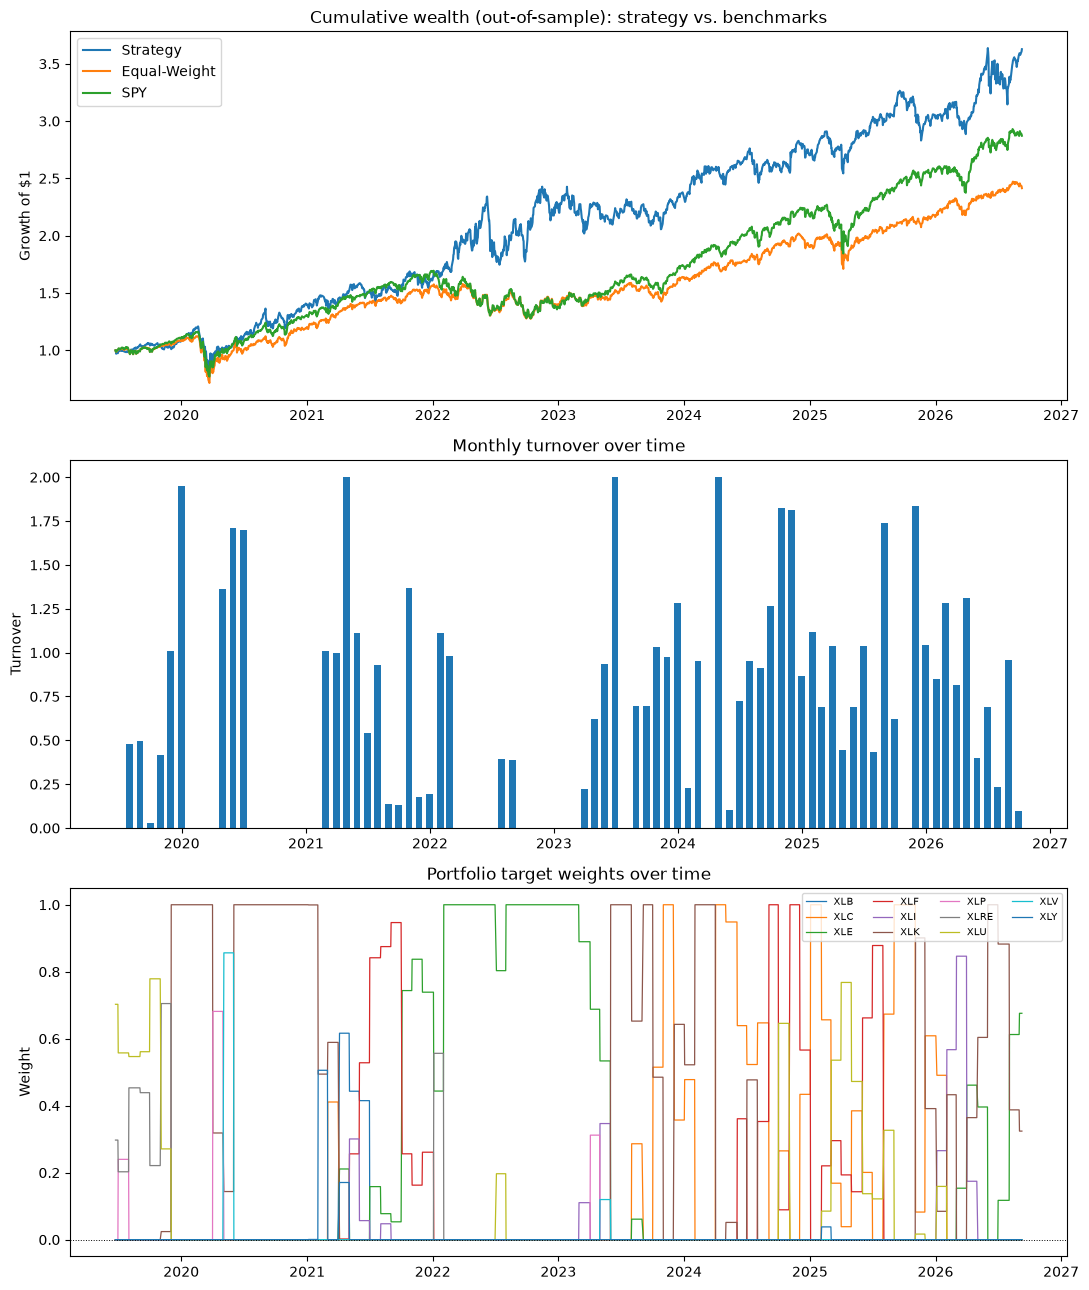

In [197]:
# ============================================================
# 5.2 Tearsheet
# ============================================================
oos_dates   = walk_forward_results.index
strategy_r  = walk_forward_results["r_net"]
ew_r        = returns.loc[oos_dates, sector_cols].mean(axis=1)   # equal-weight benchmark
spy_r       = returns.loc[oos_dates, "SPY"]                       # SPY benchmark

strat_m, strat_cum = performance_metrics(strategy_r)
ew_m,    ew_cum    = performance_metrics(ew_r)
spy_m,   spy_cum   = performance_metrics(spy_r)

# strategy-specific cost/turnover metrics
n_years = len(walk_forward_results) / 252
ann_turnover = walk_forward_results["turnover"].sum() / n_years
total_cost   = walk_forward_results["cost"].sum()   # ~ cumulative % of capital lost to costs

metric_order = ["annualized_return", "annualized_vol", "annualized_sharpe", "max_drawdown"]
tearsheet = pd.DataFrame({
    "Strategy":     {k: strat_m[k] for k in metric_order},
    "Equal-Weight": {k: ew_m[k]    for k in metric_order},
    "SPY":          {k: spy_m[k]   for k in metric_order},
}).T
tearsheet["ann_turnover"]   = [ann_turnover, np.nan, np.nan]
tearsheet["total_cost_%cap"] = [total_cost, np.nan, np.nan]
print(tearsheet.round(4))

# --- Plots ---
fig, axes = plt.subplots(3, 1, figsize=(11, 13))

axes[0].plot(strat_cum.index, strat_cum.values, label="Strategy")
axes[0].plot(ew_cum.index,    ew_cum.values,    label="Equal-Weight")
axes[0].plot(spy_cum.index,   spy_cum.values,   label="SPY")
axes[0].set_title("Cumulative wealth (out-of-sample): strategy vs. benchmarks")
axes[0].set_ylabel("Growth of $1"); axes[0].legend()

monthly_turnover = walk_forward_results["turnover"].resample("ME").sum()
axes[1].bar(monthly_turnover.index, monthly_turnover.values, width=20)
axes[1].set_title("Monthly turnover over time"); axes[1].set_ylabel("Turnover")

weight_cols = [c for c in walk_forward_results.columns if c.startswith("w_")]
for col in weight_cols:
    axes[2].plot(walk_forward_results.index, walk_forward_results[col],
                 label=col.replace("w_", ""), linewidth=0.9)
axes[2].axhline(0, color="black", linewidth=0.7, linestyle=":")
axes[2].set_title("Portfolio target weights over time")
axes[2].set_ylabel("Weight"); axes[2].legend(ncol=4, fontsize=7)

plt.tight_layout(); plt.show()

Based on this backtest and the analysis performed here we have reason to believe this portfolio strategy will outperform the benchmarks (SPY and Equal weight). We do see a nortably higher volatility over time with our strategy, but the backtested returns suggest we are going to be compensated for that risk with higher returns. So as long as the clients have the stomach for the volatility, the strategy will pay off. 

#### 5.3 - Interpretation


We see our strategy do a substantial job of outperforming the benchmarks over time. Starting in 2022 we see our strategy really break apart from the benchmarks and maintain that edge to date. Perhaps this was a rebalance our of real estate that our model managed to capture during the rising interest rate period of 2022. 

The addition of transaction costs in 4.2 caused our performance against the benchmarks to degrade but not substantially. We chose c = 5bps with weekly rebalancing as the optimal strategy, and it seems to have paid off. 

As our model progressed through time it really started to hedge away from XLE and bring in a greater concentration of XLC and XLF. Compared to the period 2022-2024 where we saw a much larger concentration in XLE, the later years really diversified into several sectors. The model seems to do a good job of self-regulating and making changes over time without getting too locked into one sector or another. 

Personally I try to be mindful of changing economic landscapes and changes in historical norms. For that reason, I would want to perform deeper research into the covariances between each sector. I beleive that some sectors start to align over time as their business cycles start to flow together. A prime example would be technology and finance as tech companies have started issuing debt to fuel their AI buidouts. Such changes in pracices may cause historical correlations between the two sectors to change. 